# 05. Kinematic Task-Level XAI

258 participants, 14 handwriting tasks, six saved outer folds, seed 42.
Notebook chỉ đọc artifact; **bảng số ở trước biểu đồ**, không fit lại mô hình.
Attribution raw ở log-odds; signed task sum và absolute attribution mass được tách riêng.

LOTO có huấn luyện lại và test-time median replacement là hai thí nghiệm khác nhau.
Các bảng outer-test là thăm dò, không dùng để lựa chọn kiến trúc rồi coi cùng Test là đánh giá mới độc lập.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
OUT = ROOT / 'results/kinematic_xai'
TABLES = OUT / 'exploratory/tables'
pd.set_option('display.max_columns', 40)
def table(name):
    return pd.read_csv(TABLES / (name + '.csv'))
def show(name):
    display(Image(filename=str(OUT / 'figures' / (name + '.png'))))
print('Kinematic XAI; source HEAD:', json.loads((OUT/'provenance.json').read_text())['head'])

Kinematic XAI; source HEAD: a2f257a71020c530bc7dca338e3780069c9da85d


## Kết quả số cuối cùng
Metric lưu dạng tỷ lệ; nhân 100 để đọc %. Delta là ablated − baseline. SD qua sáu fold không phải CI.

In [2]:
ablation = table('task_ablation_summary')
display(ablation.loc[ablation.method=='original_baseline', ['method','accuracy','f1_macro','auc','balanced_accuracy','mean_f1_macro','std_f1_macro']])
display(ablation[ablation.method=='leave_one_task_out_refit'].sort_values('f1_macro',ascending=False))
display(ablation[ablation.method=='test_time_train_median'].sort_values('f1_macro',ascending=False))

,method,accuracy,f1_macro,auc,balanced_accuracy,mean_f1_macro,std_f1_macro
0,original_baseline,0.848837,0.847163,0.906902,0.847461,0.847047,0.032387


,method,task,accuracy,f1_macro,auc,balanced_accuracy,mean_f1_macro,mean_accuracy,mean_auc,mean_balanced_accuracy,std_f1_macro,std_accuracy,std_auc,std_balanced_accuracy,delta_f1_macro,delta_accuracy,delta_auc,delta_balanced_accuracy,mean_delta_f1_macro,mean_delta_accuracy,mean_delta_auc,mean_delta_balanced_accuracy,std_delta_f1_macro,std_delta_accuracy,std_delta_auc,std_delta_balanced_accuracy,corrected,harmed,unchanged_correct,unchanged_wrong
22,leave_one_task_out_refit,small-spiral-precise,0.841085,0.838106,0.904044,0.836212,0.838014,0.841085,0.900791,0.836572,0.050449,0.049697,0.042130,0.050243,-0.009057,-0.007752,-0.002858,-0.011250,-0.009033,-0.007752,-3.235444e-03,-0.010704,0.036335,0.035013,0.019490,0.037267,7.0,9.0,210.0,32.0
20,leave_one_task_out_refit,combined-loops-fast,0.837209,0.835539,0.905807,0.836120,0.835379,0.837209,0.904027,0.835863,0.048531,0.048782,0.029932,0.048081,-0.011624,-0.011628,-0.001095,-0.011341,-0.011668,-0.011628,-1.850372e-17,-0.011413,0.038295,0.038213,0.007339,0.038098,6.0,9.0,210.0,33.0
2,leave_one_task_out_refit,RCFT-recognition,0.833333,0.830892,0.906902,0.830070,0.830937,0.833333,0.905861,0.830171,0.034212,0.034232,0.023168,0.033797,-0.016271,-0.015504,0.000000,-0.017391,-0.016110,-0.015504,1.833842e-03,-0.017105,0.043767,0.043300,0.012815,0.043378,6.0,10.0,209.0,33.0
14,leave_one_task_out_refit,upper-loops-fast,0.829457,0.827708,0.902159,0.828276,0.827687,0.829457,0.901862,0.828526,0.043064,0.043300,0.035726,0.042523,-0.019456,-0.019380,-0.004743,-0.019185,-0.019359,-0.019380,-2.164378e-03,-0.018750,0.027018,0.027187,0.010687,0.026187,5.0,10.0,209.0,34.0
4,leave_one_task_out_refit,RCFT-recall,0.825581,0.824184,0.904287,0.825631,0.823900,0.825581,0.907644,0.825378,0.041753,0.040946,0.034740,0.042994,-0.022979,-0.023256,-0.002615,-0.021830,-0.023146,-0.023256,3.616832e-03,-0.021898,0.025980,0.025475,0.018535,0.026841,7.0,13.0,206.0,32.0
24,leave_one_task_out_refit,lower-loops-precise,0.825581,0.823026,0.902220,0.822226,0.822788,0.825581,0.901131,0.821792,0.034248,0.035269,0.029704,0.032551,-0.024137,-0.023256,-0.004682,-0.025236,-0.024258,-0.023256,-2.895372e-03,-0.025485,0.039410,0.038914,0.014418,0.039808,5.0,11.0,208.0,34.0
10,leave_one_task_out_refit,small-spiral-fast,0.825581,0.822311,0.901064,0.820523,0.822104,0.825581,0.898948,0.820705,0.051522,0.050417,0.031940,0.051883,-0.024852,-0.023256,-0.005838,-0.026938,-0.024943,-0.023256,-5.078820e-03,-0.026572,0.033665,0.032889,0.016273,0.033910,5.0,11.0,208.0,34.0
6,leave_one_task_out_refit,dictation,0.821705,0.818165,0.889450,0.816175,0.818140,0.821705,0.888720,0.816168,0.042960,0.043300,0.045401,0.042432,-0.028998,-0.027132,-0.017452,-0.031286,-0.028907,-0.027132,-1.530638e-02,-0.031109,0.046193,0.045135,0.021937,0.046779,6.0,13.0,206.0,33.0
26,leave_one_task_out_refit,combined-loops-precise,0.817829,0.815812,0.905260,0.816084,0.815632,0.817829,0.901850,0.815761,0.049416,0.049697,0.030505,0.048705,-0.031351,-0.031008,-0.001642,-0.031377,-0.031415,-0.031008,-2.177091e-03,-0.031515,0.031849,0.031773,0.008753,0.031702,3.0,11.0,208.0,36.0
12,leave_one_task_out_refit,saw-fast,0.817829,0.815498,0.900517,0.815233,0.815456,0.817829,0.899673,0.815588,0.047521,0.047471,0.036231,0.047123,-0.031665,-0.031008,-0.006385,-0.032229,-0.031590,-0.031008,-4.354183e-03,-0.031689,0.024306,0.024019,0.012960,0.024194,6.0,14.0,205.0,33.0


,method,task,accuracy,f1_macro,auc,balanced_accuracy,mean_f1_macro,mean_accuracy,mean_auc,mean_balanced_accuracy,std_f1_macro,std_accuracy,std_auc,std_balanced_accuracy,delta_f1_macro,delta_accuracy,delta_auc,delta_balanced_accuracy,mean_delta_f1_macro,mean_delta_accuracy,mean_delta_auc,mean_delta_balanced_accuracy,std_delta_f1_macro,std_delta_accuracy,std_delta_auc,std_delta_balanced_accuracy,corrected,harmed,unchanged_correct,unchanged_wrong
19,test_time_train_median,combined-loops-fast,0.848837,0.847404,0.905382,0.848313,0.847212,0.848837,0.904392,0.848039,0.035434,0.035269,0.029648,0.035469,0.000241,0.000000,-0.001520,0.000851,0.000165,-1.676899e-17,0.000365,0.000763,0.014864,0.014708,0.002915,0.015242,2.0,2.0,217.0,37.0
13,test_time_train_median,upper-loops-fast,0.848837,0.847163,0.904895,0.847461,0.846905,0.848837,0.901103,0.847057,0.035951,0.035269,0.029235,0.036301,0.000000,0.000000,-0.002007,0.000000,-0.000142,-1.676899e-17,-0.002924,-0.000219,0.014605,0.014708,0.005830,0.014757,2.0,2.0,217.0,37.0
25,test_time_train_median,combined-loops-precise,0.848837,0.846903,0.908179,0.846610,0.846781,0.848837,0.905482,0.846513,0.032637,0.032056,0.034040,0.032854,-0.000260,0.000000,0.001277,-0.000851,-0.000266,5.782412e-19,0.001456,-0.000763,0.020838,0.020801,0.004307,0.020148,3.0,3.0,216.0,36.0
11,test_time_train_median,saw-fast,0.844961,0.843113,0.910611,0.843113,0.843041,0.844961,0.908772,0.843041,0.038601,0.037977,0.023497,0.038601,-0.004050,-0.003876,0.003709,-0.004348,-0.004005,-3.875969e-03,0.004745,-0.004235,0.017513,0.017506,0.010232,0.017272,1.0,2.0,217.0,38.0
7,test_time_train_median,big-spiral-fast,0.844961,0.842836,0.906233,0.842262,0.842668,0.844961,0.904389,0.841977,0.035309,0.035013,0.031730,0.035110,-0.004327,-0.003876,-0.000669,-0.005199,-0.004378,-3.875969e-03,0.000362,-0.005300,0.009830,0.009494,0.004886,0.010527,2.0,3.0,216.0,37.0
21,test_time_train_median,small-spiral-precise,0.841085,0.839812,0.902888,0.841320,0.839649,0.841085,0.897842,0.841246,0.045740,0.045135,0.036843,0.045625,-0.007351,-0.007752,-0.004013,-0.006142,-0.007398,-7.751938e-03,-0.006185,-0.006031,0.024985,0.024019,0.011262,0.026496,4.0,6.0,213.0,35.0
9,test_time_train_median,small-spiral-fast,0.841085,0.838106,0.903861,0.836212,0.838112,0.841085,0.901109,0.836421,0.037407,0.037258,0.030557,0.037245,-0.009057,-0.007752,-0.003040,-0.011250,-0.008935,-7.751938e-03,-0.002918,-0.010855,0.044181,0.043300,0.010440,0.044403,6.0,8.0,211.0,33.0
3,test_time_train_median,RCFT-recall,0.837209,0.836017,0.907206,0.837823,0.835989,0.837209,0.906191,0.837773,0.048762,0.048782,0.037927,0.047951,-0.011146,-0.011628,0.000304,-0.009638,-0.011058,-1.162791e-02,0.002164,-0.009503,0.031502,0.032056,0.017233,0.029970,5.0,8.0,211.0,34.0
17,test_time_train_median,rainbow-fast,0.837209,0.835788,0.907267,0.836972,0.835338,0.837209,0.907310,0.836860,0.034270,0.032889,0.036519,0.037285,-0.011375,-0.011628,0.000365,-0.010490,-0.011708,-1.162791e-02,0.003283,-0.010417,0.024978,0.024391,0.008175,0.026387,2.0,5.0,214.0,37.0
23,test_time_train_median,lower-loops-precise,0.829457,0.828208,0.900152,0.829979,0.827997,0.829457,0.902581,0.830203,0.041056,0.040725,0.028286,0.043314,-0.018955,-0.019380,-0.006750,-0.017483,-0.019050,-1.937984e-02,-0.001446,-0.017073,0.034776,0.034232,0.006576,0.036273,2.0,7.0,212.0,37.0


## A–C. Feature, Task và Source Group
Mass = mean(sum(abs(phi))). Các signed sums được báo riêng.

In [3]:
display(table('top20_features'))
display(table('task_importance'))
display(table('group_importance'))
display(table('task_signed_summary'))

,full_name,n_features,mean_absolute_shap_mass,total_absolute_shap_mass,mass_per_feature,share_percent,participant_q25,participant_q75,fold_mass_sd,mean_rank,rank_sd,top3_count,top3_frequency,global_rank,column,task_index,task,feature_in_task,feature,group
0,copy::trajectory_width,1,0.966905,249.461608,0.966905,7.951176,0.685943,1.274767,0.118934,1.166667,0.408248,6,1.000000,1.0,1000,13,copy,38,trajectory_width,trajectory
1,copy::fft_pressure_dominant_hz,1,0.709768,183.120137,0.709768,5.836651,0.412322,0.968679,0.125363,2.000000,0.632456,6,1.000000,2.0,1032,13,copy,70,fft_pressure_dominant_hz,fft
2,copy::statistics_acc_skew,1,0.466059,120.243331,0.466059,3.832557,0.301326,0.581834,0.176833,4.833333,2.639444,2,0.333333,3.0,1011,13,copy,49,statistics_acc_skew,statistics
3,copy::trajectory_duration,1,0.418496,107.971914,0.418496,3.441426,0.271630,0.563501,0.121644,5.500000,3.391165,2,0.333333,4.0,997,13,copy,35,trajectory_duration,trajectory
4,copy::trajectory_bbox_area,1,0.386296,99.664296,0.386296,3.176634,0.236523,0.512144,0.152826,6.833333,3.488075,1,0.166667,5.0,1002,13,copy,40,trajectory_bbox_area,trajectory
5,RCFT-recall::statistics_acc_kurtosis,1,0.358044,92.375265,0.358044,2.944309,0.187429,0.447405,0.148160,8.166667,5.076088,1,0.166667,6.0,124,1,RCFT-recall,50,statistics_acc_kurtosis,statistics
6,lower-loops-precise::fft_y_bandwidth_hz,1,0.255943,66.033419,0.255943,2.104706,0.154299,0.307879,0.065836,10.166667,4.915960,0,0.000000,7.0,878,11,lower-loops-precise,64,fft_y_bandwidth_hz,fft
7,dictation::orientation_azimuth_std,1,0.251798,64.963980,0.251798,2.070619,0.124159,0.319090,0.128888,12.333333,5.853774,0,0.000000,8.0,182,2,dictation,34,orientation_azimuth_std,orientation
8,lower-loops-fast::pressure_std,1,0.242270,62.505642,0.242270,1.992264,0.132823,0.275358,0.077232,11.500000,6.774954,0,0.000000,9.0,542,7,lower-loops-fast,24,pressure_std,pressure
9,dictation::energy_y_rms,1,0.236853,61.108139,0.236853,1.947721,0.088984,0.333205,0.106698,12.666667,7.737355,0,0.000000,10.0,204,2,dictation,56,energy_y_rms,energy


,task,n_features,mean_absolute_shap_mass,total_absolute_shap_mass,mass_per_feature,share_percent,participant_q25,participant_q75,fold_mass_sd,mean_rank,rank_sd,top3_count,top3_frequency,global_rank
0,copy,74,4.297703,1108.807324,0.058077,35.341398,3.874194,4.752082,0.120311,1.000000,0.000000,6,1.000000,1.0
1,dictation,74,1.363045,351.665659,0.018420,11.208761,1.153915,1.568183,0.225283,2.333333,0.516398,6,1.000000,2.0
2,lower-loops-fast,74,1.014206,261.665055,0.013705,8.340140,0.733769,1.187426,0.207969,3.666667,1.032796,2,0.333333,3.0
3,small-spiral-fast,74,0.894051,230.665046,0.012082,7.352066,0.716066,1.024217,0.148123,4.333333,0.816497,1,0.166667,4.0
4,RCFT-recall,74,0.868699,224.124295,0.011739,7.143591,0.622727,0.994214,0.241988,4.833333,1.940790,2,0.333333,5.0
5,RCFT-recognition,74,0.697872,180.050915,0.009431,5.738825,0.488095,0.846283,0.200351,5.833333,2.041241,1,0.166667,6.0
6,lower-loops-precise,74,0.682151,175.995033,0.009218,5.609550,0.521233,0.797013,0.132259,6.666667,1.366260,0,0.000000,7.0
7,small-spiral-precise,74,0.497038,128.235871,0.006717,4.087306,0.322830,0.621558,0.155499,8.833333,1.940790,0,0.000000,8.0
8,big-spiral-fast,74,0.378526,97.659732,0.005115,3.112742,0.293253,0.447274,0.072096,9.833333,1.471960,0,0.000000,9.0
9,rainbow-fast,74,0.307805,79.413706,0.004160,2.531180,0.158275,0.420637,0.155557,10.666667,3.076795,0,0.000000,10.0


,group,n_features,mean_absolute_shap_mass,total_absolute_shap_mass,mass_per_feature,share_percent,participant_q25,participant_q75,fold_mass_sd,mean_rank,rank_sd,top3_count,top3_frequency,global_rank
0,fft,224,3.400340,877.287698,0.015180,27.962093,2.950150,3.838366,0.373143,1.166667,0.408248,6,1.0,1.0
1,statistics,140,2.625793,677.454716,0.018756,21.592747,2.297152,2.942557,0.267184,2.166667,0.752773,6,1.0,2.0
2,trajectory,112,2.465493,636.097199,0.022013,20.274545,2.145251,2.860370,0.251436,2.666667,0.516398,6,1.0,3.0
3,orientation,56,1.039268,268.131203,0.018558,8.546238,0.768445,1.221390,0.262061,4.000000,0.000000,0,0.0,4.0
4,pressure,112,0.589001,151.962334,0.005259,4.843548,0.430487,0.672294,0.132189,5.500000,0.547723,0,0.0,5.0
5,acceleration,84,0.473395,122.135870,0.005636,3.892879,0.327259,0.556626,0.182866,6.833333,1.602082,0,0.0,6.0
6,energy,42,0.452755,116.810891,0.010780,3.723154,0.280182,0.587954,0.144814,6.666667,1.211060,0,0.0,7.0
7,jerk,42,0.411879,106.264814,0.009807,3.387015,0.276173,0.506235,0.104193,7.666667,1.366260,0,0.0,8.0
8,peaks,42,0.277654,71.634834,0.006611,2.283242,0.193741,0.342420,0.080671,8.833333,1.169045,0,0.0,9.0
9,velocity,112,0.157325,40.589754,0.001405,1.293731,0.118028,0.183179,0.032445,10.500000,0.836660,0,0.0,10.0


,task,mean_signed_log_odds,mean_absolute_net_log_odds,mean_absolute_feature_mass
0,RCFT-recognition,-0.030714,0.301338,0.697872
1,RCFT-recall,-0.015772,0.498532,0.868699
2,dictation,0.002930,0.558853,1.363045
3,big-spiral-fast,-0.014646,0.132034,0.378526
4,small-spiral-fast,-0.016040,0.398385,0.894051
5,saw-fast,0.005945,0.144024,0.290822
6,upper-loops-fast,0.006961,0.128292,0.299191
7,lower-loops-fast,-0.017777,0.563326,1.014206
8,rainbow-fast,0.022188,0.139546,0.307805
9,combined-loops-fast,0.001564,0.141746,0.296422


In [4]:
display(table('task_group_matrix').pivot(index='task',columns='group',values='mean_absolute_shap_mass'))
display(table('task_importance_by_fold'))

group,acceleration,curvature,energy,fft,jerk,lifts,orientation,peaks,pressure,statistics,trajectory,velocity
task,,,,,,,,,,,,
RCFT-recall,0.070889,0.008324,0.023426,0.081956,0.017504,0.003213,0.041126,0.003344,0.030082,0.549818,0.028518,0.010499
RCFT-recognition,0.080232,0.001005,0.015607,0.167691,0.002317,0.029567,0.093008,0.008865,0.036095,0.226401,0.030008,0.007077
big-spiral-fast,0.022741,0.000302,0.008941,0.113137,0.015841,0.000000,0.071043,0.003594,0.020542,0.097143,0.014959,0.010282
combined-loops-fast,0.025407,0.003875,0.007767,0.031632,0.101971,0.003960,0.009916,0.004396,0.016684,0.053061,0.025597,0.012157
combined-loops-precise,0.021649,0.005065,0.001649,0.109158,0.001630,0.000701,0.012098,0.044807,0.007382,0.041110,0.007271,0.020483
copy,0.107226,0.004518,0.077803,1.173381,0.131035,0.035939,0.173610,0.010482,0.011707,0.728501,1.830422,0.013079
dictation,0.078044,0.015629,0.237543,0.089290,0.127802,0.038183,0.340664,0.062151,0.046007,0.134509,0.177865,0.015357
lower-loops-fast,0.013360,0.084037,0.007417,0.103274,0.002430,0.015177,0.145104,0.060649,0.261326,0.284159,0.021477,0.015797
lower-loops-precise,0.008800,0.002343,0.013201,0.476985,0.003219,0.000459,0.032557,0.004096,0.038957,0.065541,0.027214,0.008779


,fold,task,mean_absolute_shap_mass,rank
0,0,RCFT-recognition,0.700980,7.0
1,0,RCFT-recall,0.996994,3.0
2,0,dictation,1.340920,2.0
3,0,big-spiral-fast,0.304448,12.0
4,0,small-spiral-fast,0.861880,5.0
...,...,...,...,...
79,5,combined-loops-fast,0.322342,10.0
80,5,small-spiral-precise,0.608655,7.0
81,5,lower-loops-precise,0.869539,6.0
82,5,combined-loops-precise,0.287774,11.0


## D–F. Kiểm chứng bằng permutation, ablation và stability
Permutation có thể tạo tổ hợp out-of-distribution; 30 repeats/fold được trung bình trong fold trước khi tính fold SD.

In [5]:
display(table('permutation_importance'))
display(table('method_agreement'))
display(table('method_concordance'))
display(table('fold_stability_summary'))

,level,block,drop_f1_macro_mean,drop_f1_macro_std,drop_accuracy_mean,drop_accuracy_std,drop_auc_mean,drop_auc_std,drop_balanced_accuracy_mean,drop_balanced_accuracy_std
0,task,RCFT-recognition,0.026094,0.009981,0.025194,0.010374,0.004439,0.008627,0.026533,0.008989
1,task,RCFT-recall,0.024024,0.025804,0.023256,0.025598,0.007506,0.013760,0.024309,0.024935
2,task,dictation,0.030779,0.035206,0.029716,0.034860,0.013579,0.012872,0.031686,0.034889
3,task,big-spiral-fast,0.012724,0.007558,0.012532,0.007279,0.001736,0.005764,0.012754,0.008035
4,task,small-spiral-fast,0.019888,0.023125,0.019251,0.022719,0.008456,0.008746,0.020284,0.023178
5,task,saw-fast,0.008038,0.009492,0.007752,0.009302,-0.002815,0.003847,0.008265,0.009588
6,task,upper-loops-fast,0.002892,0.007205,0.002842,0.007478,0.001497,0.003754,0.002811,0.006568
7,task,lower-loops-fast,0.042495,0.022750,0.041990,0.023346,0.020992,0.013305,0.041969,0.020981
8,task,rainbow-fast,0.009761,0.014118,0.009690,0.014029,0.001258,0.002512,0.009277,0.013878
9,task,combined-loops-fast,0.004436,0.010563,0.004651,0.010458,-0.000829,0.003023,0.003698,0.010735


,task,shap_mass,shap_rank,permutation_f1_drop,test_time_train_median_f1_drop,leave_one_task_out_refit_f1_drop,permutation_rank,test_time_train_median_rank,leave_one_task_out_refit_rank,shap_loto_rank_gap,top3_shap_and_permutation,top3_all_three_methods
0,copy,4.297703,1.0,0.223869,0.131165,0.118027,1.0,1.0,1.0,0.0,True,True
1,dictation,1.363045,2.0,0.030779,0.024483,0.028998,3.0,4.0,7.0,5.0,True,False
2,lower-loops-fast,1.014206,3.0,0.042495,0.034335,0.039868,2.0,2.0,3.0,0.0,True,True
3,small-spiral-fast,0.894051,4.0,0.019888,0.009057,0.024852,6.0,8.0,8.0,4.0,False,False
4,RCFT-recall,0.868699,5.0,0.024024,0.011146,0.022979,5.0,7.0,10.0,5.0,False,False
5,RCFT-recognition,0.697872,6.0,0.026094,0.032002,0.016271,4.0,3.0,12.0,6.0,False,False
6,lower-loops-precise,0.682151,7.0,0.018695,0.018955,0.024137,7.0,5.0,9.0,2.0,False,False
7,small-spiral-precise,0.497038,8.0,0.008390,0.007351,0.009057,10.0,9.0,14.0,6.0,False,False
8,big-spiral-fast,0.378526,9.0,0.012724,0.004327,0.051863,8.0,10.0,2.0,7.0,False,False
9,rainbow-fast,0.307805,10.0,0.009761,0.011375,0.031665,9.0,6.0,4.5,5.5,False,False


,level,comparison,metric,n_blocks,spearman
0,task,SHAP_vs_permutation,f1_macro,14,0.947253
1,task,SHAP_vs_permutation,accuracy,14,0.947253
2,task,SHAP_vs_permutation,auc,14,0.973626
3,task,SHAP_vs_permutation,balanced_accuracy,14,0.925275
4,task,SHAP_vs_test_time_train_median,f1_macro,14,0.841758
5,task,SHAP_vs_test_time_train_median,accuracy,14,0.850524
6,task,SHAP_vs_test_time_train_median,auc,14,0.810989
7,task,SHAP_vs_test_time_train_median,balanced_accuracy,14,0.859341
8,task,SHAP_vs_leave_one_task_out_refit,f1_macro,14,0.211221
9,task,SHAP_vs_leave_one_task_out_refit,accuracy,14,0.197347


,level,top_k,mean_spearman,min_spearman,max_spearman,mean_jaccard,mean_overlap
0,feature,20,0.314940,0.277718,0.359394,0.416141,11.733333
1,group,3,0.913287,0.832168,0.965035,1.000000,3.000000
2,group,5,0.913287,0.832168,0.965035,0.755556,4.266667
3,task,3,0.822125,0.723077,0.925275,0.566667,2.133333
4,task,5,0.822125,0.723077,0.925275,0.800000,4.400000


In [6]:
display(table('participant_variability'))
display(table('correct_vs_incorrect_tasks'))
display(table('local_cases'))

,task,participant_rank_mean,participant_rank_sd,participant_top3_frequency,mass_sd,mass_min,mass_max
0,RCFT-recognition,6.031008,2.196346,0.170543,0.292859,0.327057,1.979601
1,RCFT-recall,5.290698,2.244923,0.197674,0.389983,0.229060,2.438354
2,dictation,2.697674,0.998868,0.844961,0.327003,0.632367,2.327831
3,big-spiral-fast,9.821705,1.902076,0.003876,0.123543,0.161667,0.949320
4,small-spiral-fast,4.550388,1.502067,0.263566,0.255508,0.331644,1.875814
5,saw-fast,11.468992,2.257932,0.000000,0.157170,0.064932,0.920832
6,upper-loops-fast,11.178295,1.964469,0.000000,0.103501,0.107324,0.644976
7,lower-loops-fast,4.259690,1.705565,0.379845,0.401315,0.393959,3.038000
8,rainbow-fast,11.027132,2.756535,0.011628,0.173457,0.059855,0.910118
9,combined-loops-fast,11.313953,2.194413,0.003876,0.144546,0.070647,0.824222


,correct,task,n,mean_absolute_shap_mass,median_absolute_shap_mass,mean_signed_log_odds,top3_frequency
0,True,RCFT-recognition,219,0.697266,0.616377,-0.031244,0.168950
1,True,RCFT-recall,219,0.867943,0.793921,0.005694,0.219178
2,True,dictation,219,1.367491,1.349003,-0.010184,0.844749
3,True,big-spiral-fast,219,0.378768,0.353563,-0.015696,0.004566
4,True,small-spiral-fast,219,0.879706,0.848172,-0.006468,0.251142
5,True,saw-fast,219,0.286128,0.249826,0.007360,0.000000
6,True,upper-loops-fast,219,0.298353,0.292901,0.013290,0.000000
7,True,lower-loops-fast,219,0.995462,0.916559,-0.030350,0.374429
8,True,rainbow-fast,219,0.310576,0.290920,0.016577,0.013699
9,True,combined-loops-fast,219,0.292351,0.274337,0.002298,0.004566


,category,participant_id,row,fold,label,prediction,probability,raw_score,base_value,selection_rule
0,true_negative,BR10301,0,4,0,0,0.249635,-1.100558,0.822308,lexicographically first participant ID in each...
1,true_positive,BR10306,4,5,1,1,0.996677,5.703634,0.773750,lexicographically first participant ID in each...
2,false_positive,BR2404,12,5,0,1,0.614726,0.467223,0.773750,lexicographically first participant ID in each...
3,false_negative,BR7412,106,4,1,0,0.071056,-2.570575,0.822308,lexicographically first participant ID in each...


## Thay đổi dự đoán từng participant
Giữ cả corrected, harmed, unchanged_correct và unchanged_wrong.

In [7]:
display(table('task_ablation_oof').groupby(['method','task','change']).size().unstack(fill_value=0))
display(table('task_ablation_oof').head(28))
display(table('participant_task_attributions').head(28))

change                                           corrected  harmed  \
method                   task                                        
leave_one_task_out_refit RCFT-recall                     7      13   
                         RCFT-recognition                6      10   
                         big-spiral-fast                 3      16   
                         combined-loops-fast             6       9   
                         combined-loops-precise          3      11   
                         copy                           12      42   
                         dictation                       6      13   
                         lower-loops-fast                7      17   
                         lower-loops-precise             5      11   
                         rainbow-fast                    2      10   
                         saw-fast                        6      14   
                         small-spiral-fast               5      11   
                         small-spiral-precise            7       9   
                         upper-loops-fast                5      10   
test_time_train_median   RCFT-recall                     5       8   
                         RCFT-recognition                1       9   
                         big-spiral-fast                 2       3   
                         combined-loops-fast             2       2   
                         combined-loops-precise          3       3   
                         copy                           10      43   
                         dictation                       4      10   
                         lower-loops-fast                4      13   
                         lower-loops-precise             2       7   
                         rainbow-fast                    2       5   
                         saw-fast                        1       2   
                         small-spiral-fast               6       8   
                         small-spiral-precise            4       6   
                         upper-loops-fast                2       2   

change                                           unchanged_correct  \
method                   task                                        
leave_one_task_out_refit RCFT-recall                           206   
                         RCFT-recognition                      209   
                         big-spiral-fast                       203   
                         combined-loops-fast                   210   
                         combined-loops-precise                208   
                         copy                                  177   
                         dictation                             206   
                         lower-loops-fast                      202   
                         lower-loops-precise                   208   
                         rainbow-fast                          209   
                         saw-fast                              205   
                         small-spiral-fast                     208   
                         small-spiral-precise                  210   
                         upper-loops-fast                      209   
test_time_train_median   RCFT-recall                           211   
                         RCFT-recognition                      210   
                         big-spiral-fast                       216   
                         combined-loops-fast                   217   
                         combined-loops-precise                216   
                         copy                                  176   
                         dictation                             209   
                         lower-loops-fast                      206   
                         lower-loops-precise                   212   
                         rainbow-fast                          214   
                         saw-fast                              217   
         

,fold,participant_id,label,task,method,baseline_prediction,baseline_probability,prediction,probability,probability_delta,change
0,0,BR10302,0,RCFT-recognition,test_time_train_median,0,0.046320,0,0.056758,0.010438,unchanged_correct
1,0,BR10403,0,RCFT-recognition,test_time_train_median,0,0.025581,0,0.018409,-0.007171,unchanged_correct
2,0,BR10406,1,RCFT-recognition,test_time_train_median,1,0.991508,1,0.995518,0.004010,unchanged_correct
3,0,BR2403,0,RCFT-recognition,test_time_train_median,0,0.351217,1,0.546661,0.195444,harmed
4,0,BR2408,0,RCFT-recognition,test_time_train_median,1,0.610705,1,0.568373,-0.042332,unchanged_wrong
5,0,BR2409,0,RCFT-recognition,test_time_train_median,0,0.059675,0,0.069072,0.009397,unchanged_correct
6,0,BR3304,0,RCFT-recognition,test_time_train_median,0,0.101650,0,0.042293,-0.059357,unchanged_correct
7,0,BR3402,0,RCFT-recognition,test_time_train_median,0,0.363918,0,0.212090,-0.151828,unchanged_correct
8,0,BR3407,0,RCFT-recognition,test_time_train_median,0,0.413685,0,0.317146,-0.096538,unchanged_correct
9,0,BR5303,0,RCFT-recognition,test_time_train_median,0,0.324316,0,0.418951,0.094636,unchanged_correct


,participant_id,fold,label,prediction,correct,task,absolute_shap_mass,signed_shap_log_odds,share_percent,rank
0,BR10301,4,0,0,True,RCFT-recognition,0.710732,-0.094419,5.663836,6.0
1,BR10301,4,0,0,True,RCFT-recall,0.725796,-0.498116,5.783883,5.0
2,BR10301,4,0,0,True,dictation,0.827140,0.316062,6.591497,3.0
3,BR10301,4,0,0,True,big-spiral-fast,0.239243,0.020001,1.906532,12.0
4,BR10301,4,0,0,True,small-spiral-fast,0.667899,0.170704,5.322495,8.0
5,BR10301,4,0,0,True,saw-fast,0.550237,-0.135555,4.384850,9.0
6,BR10301,4,0,0,True,upper-loops-fast,0.177841,-0.105310,1.417220,13.0
7,BR10301,4,0,0,True,lower-loops-fast,0.708788,-0.471334,5.648342,7.0
8,BR10301,4,0,0,True,rainbow-fast,0.296927,0.027030,2.366213,11.0
9,BR10301,4,0,0,True,combined-loops-fast,0.821169,-0.517106,6.543909,4.0


## Train-only artifacts riêng
Các artifact dưới đây chỉ dùng outer Train. Khi tích hợp vào một inner CV mới, phải gọi lại API trên inner Train; không dùng outer-Train importance để chọn task trên inner Validation nằm trong đó.

In [8]:
display(pd.read_csv(OUT/'train_only/fold_task_importance.csv'))
print('Không có task subset/weight nào được chọn trong nghiên cứu này.')

,task,mean_absolute_shap_mass,rank,outer_fold
0,RCFT-recognition,0.429365,10.0,0
1,RCFT-recall,0.824708,3.0,0
2,dictation,1.109799,2.0,0
3,big-spiral-fast,0.567394,7.0,0
4,small-spiral-fast,0.703808,5.0,0
...,...,...,...,...
79,combined-loops-fast,0.235757,13.0,5
80,small-spiral-precise,0.315812,11.0,5
81,lower-loops-precise,0.618313,6.0,5
82,combined-loops-precise,0.363304,9.0,5


Không có task subset/weight nào được chọn trong nghiên cứu này.


## Biểu đồ feature/task/group

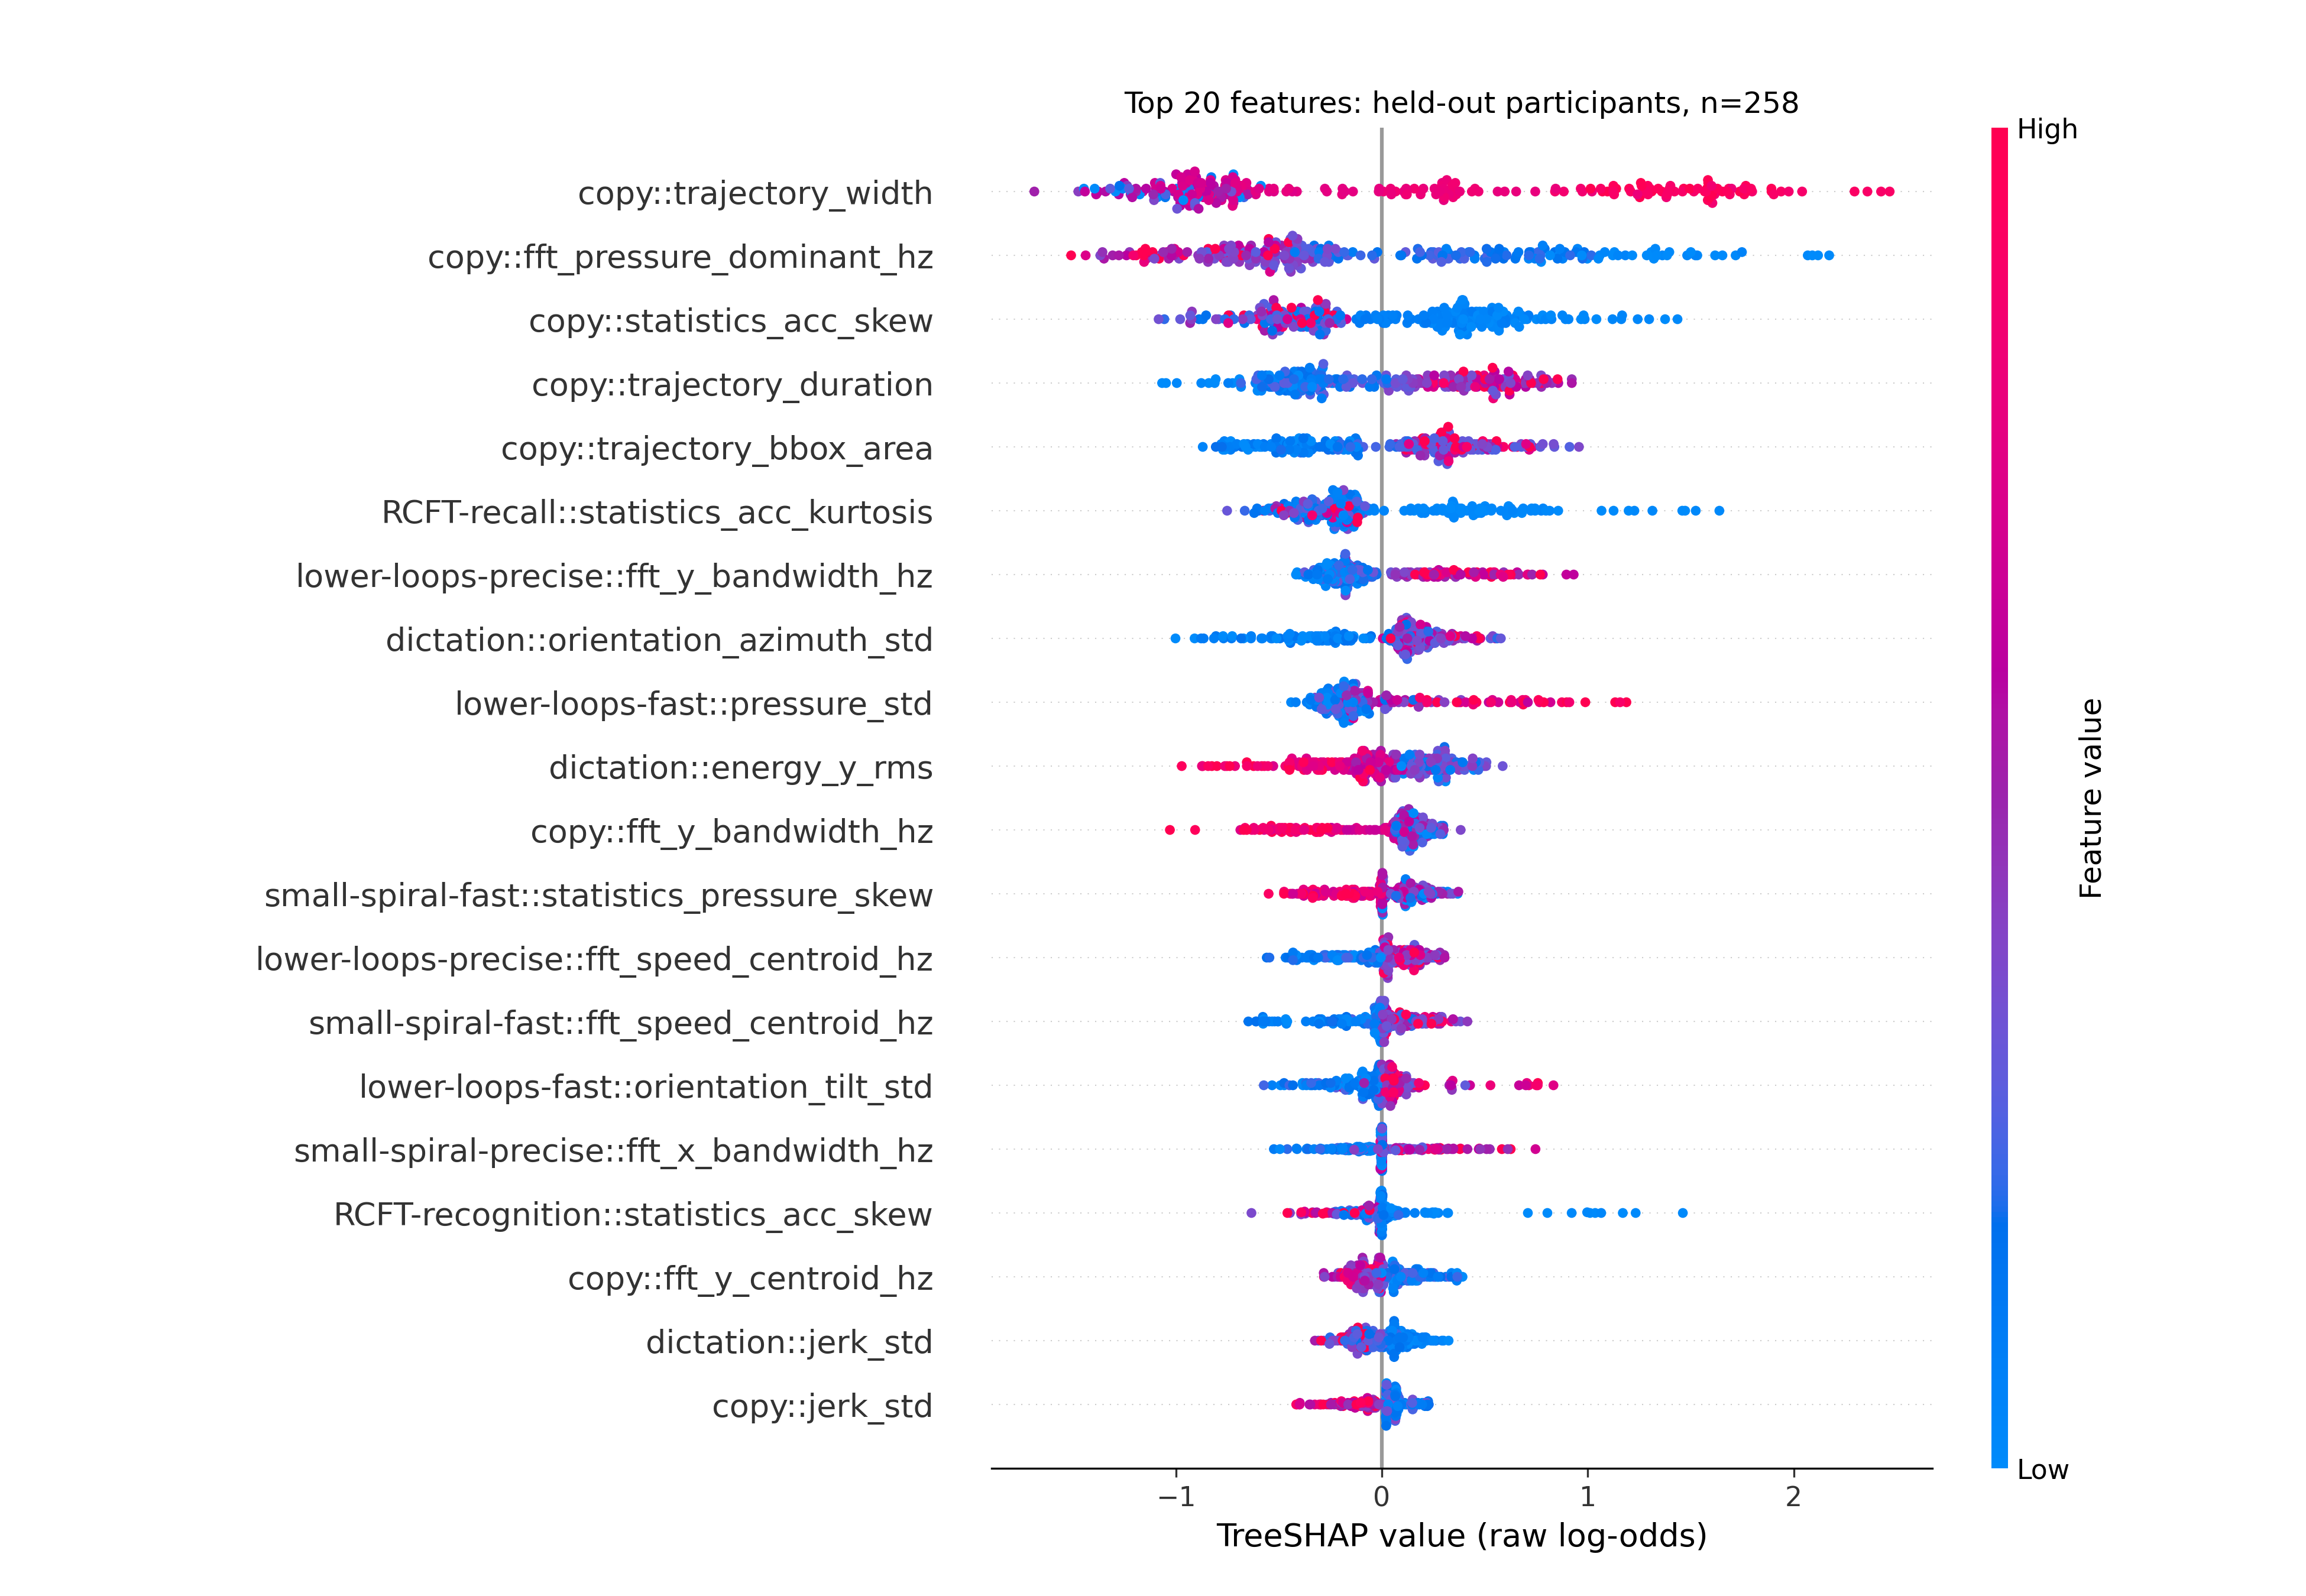

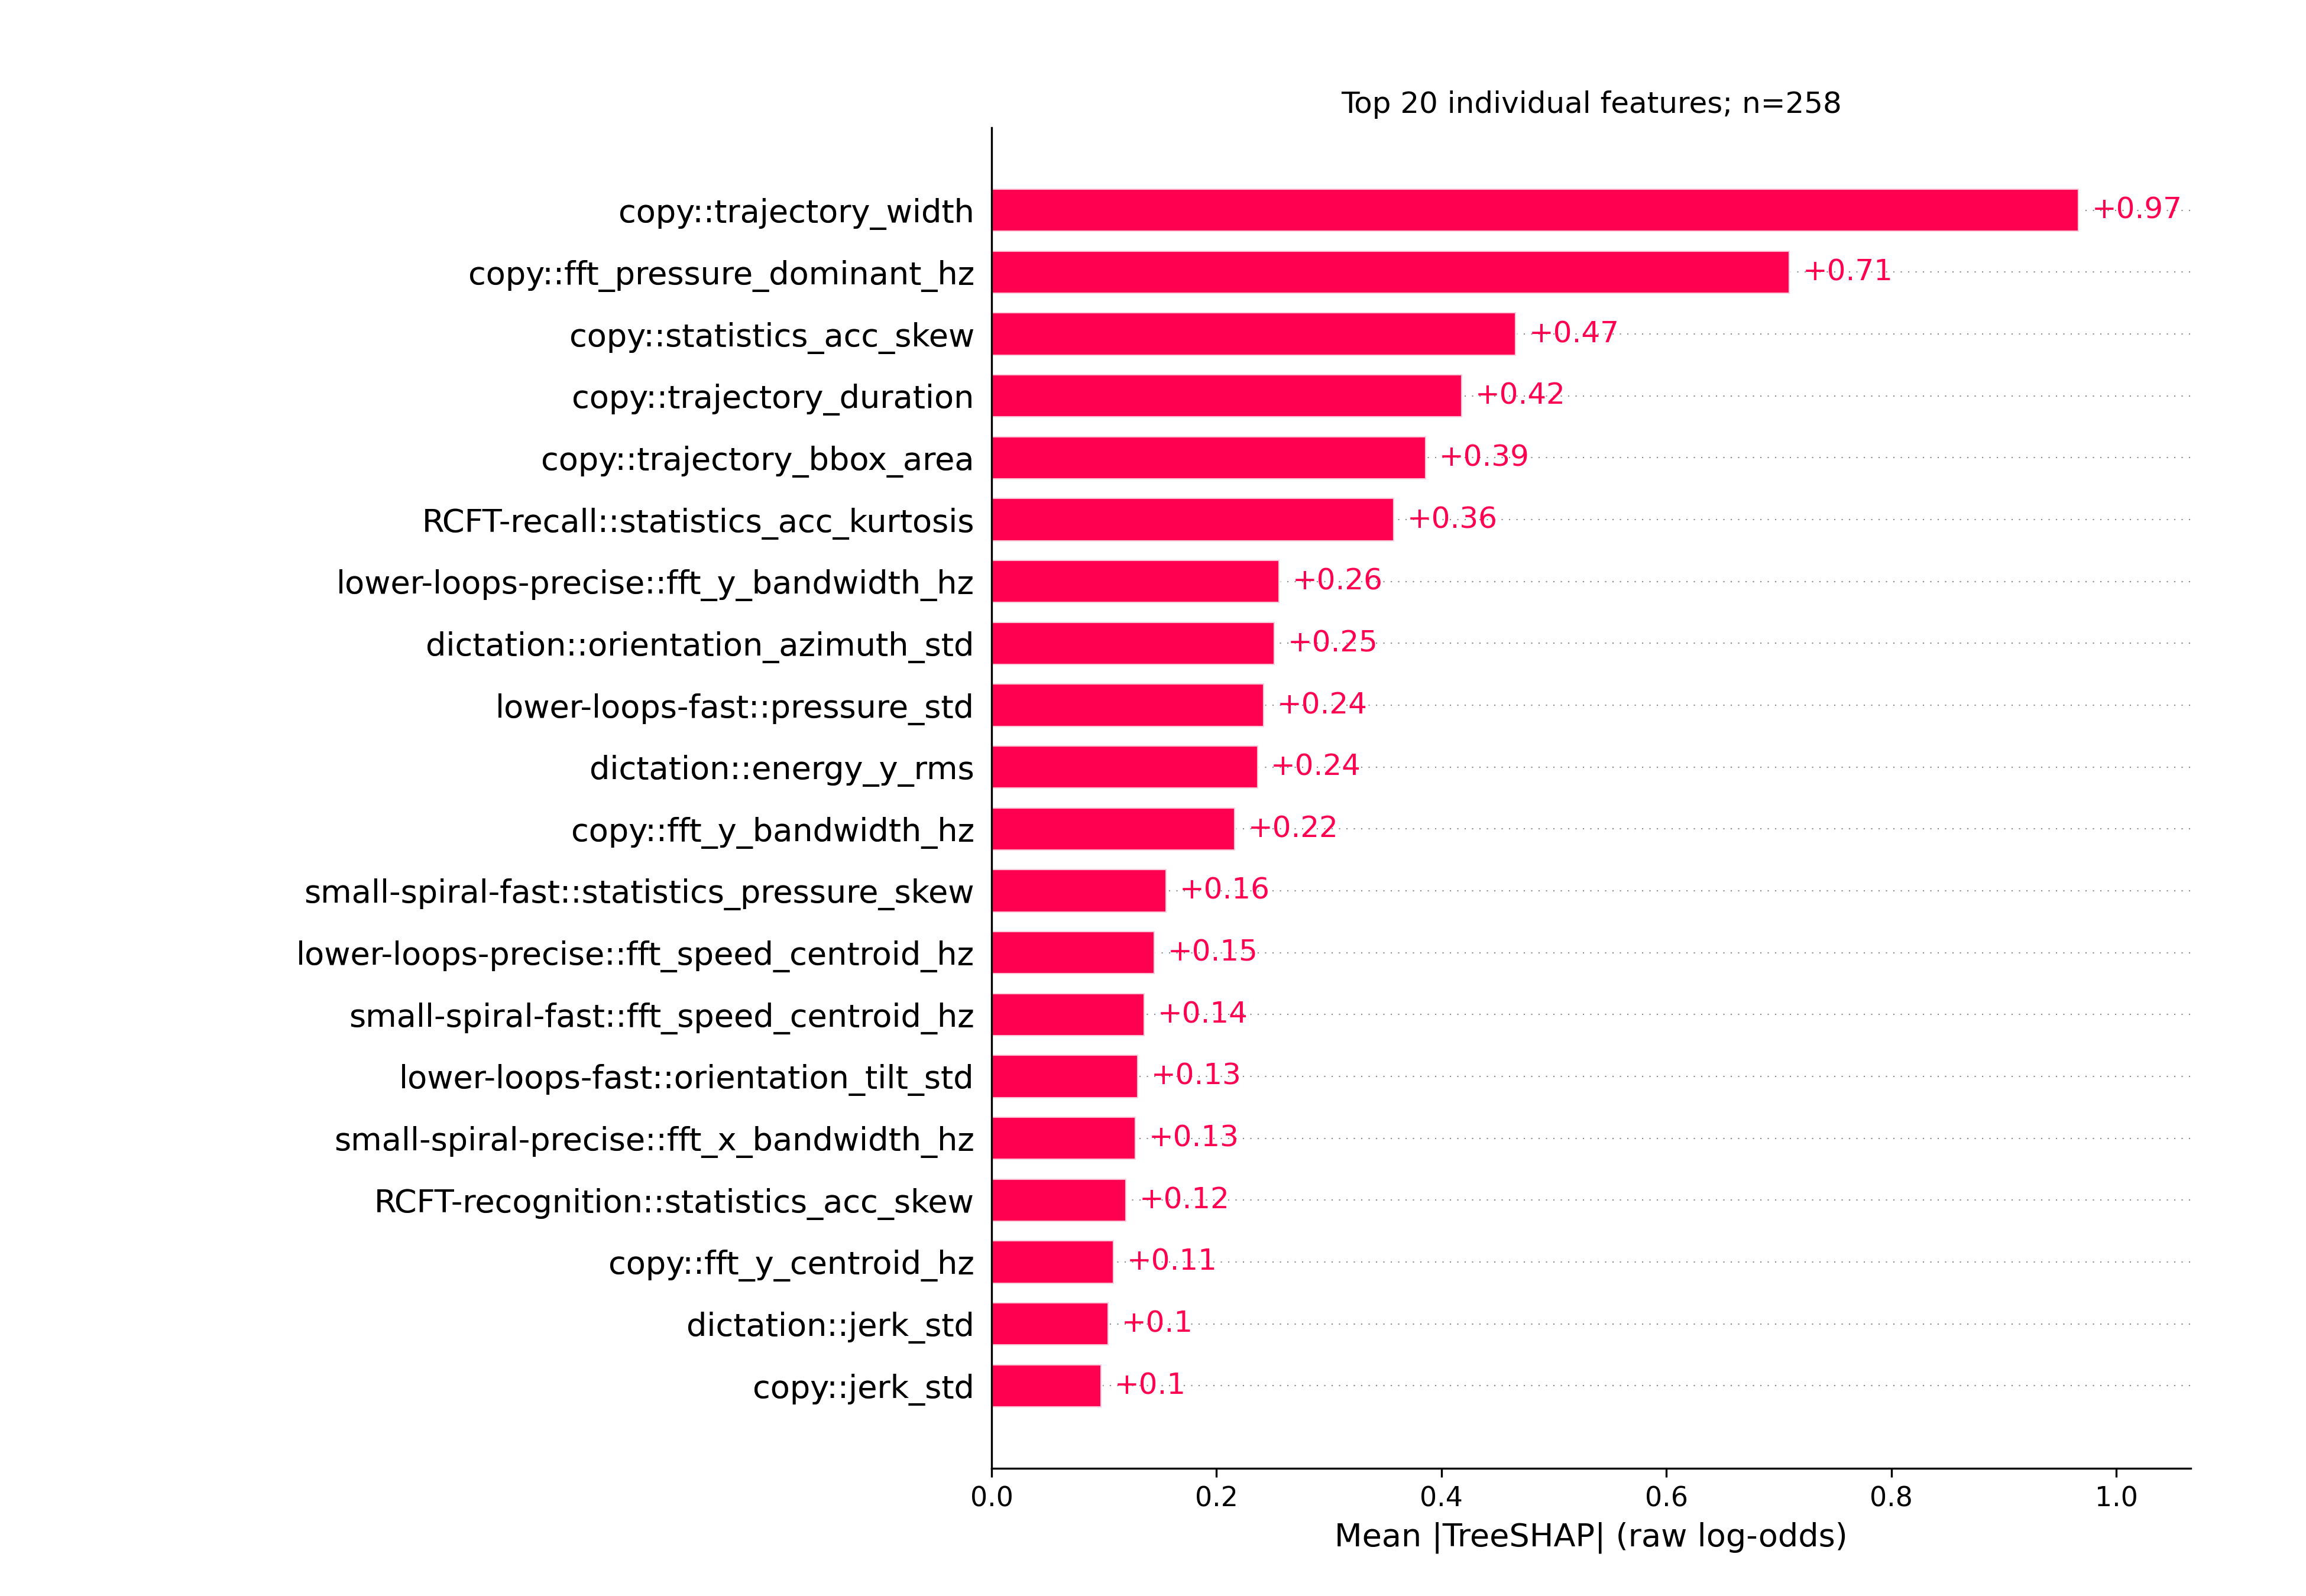

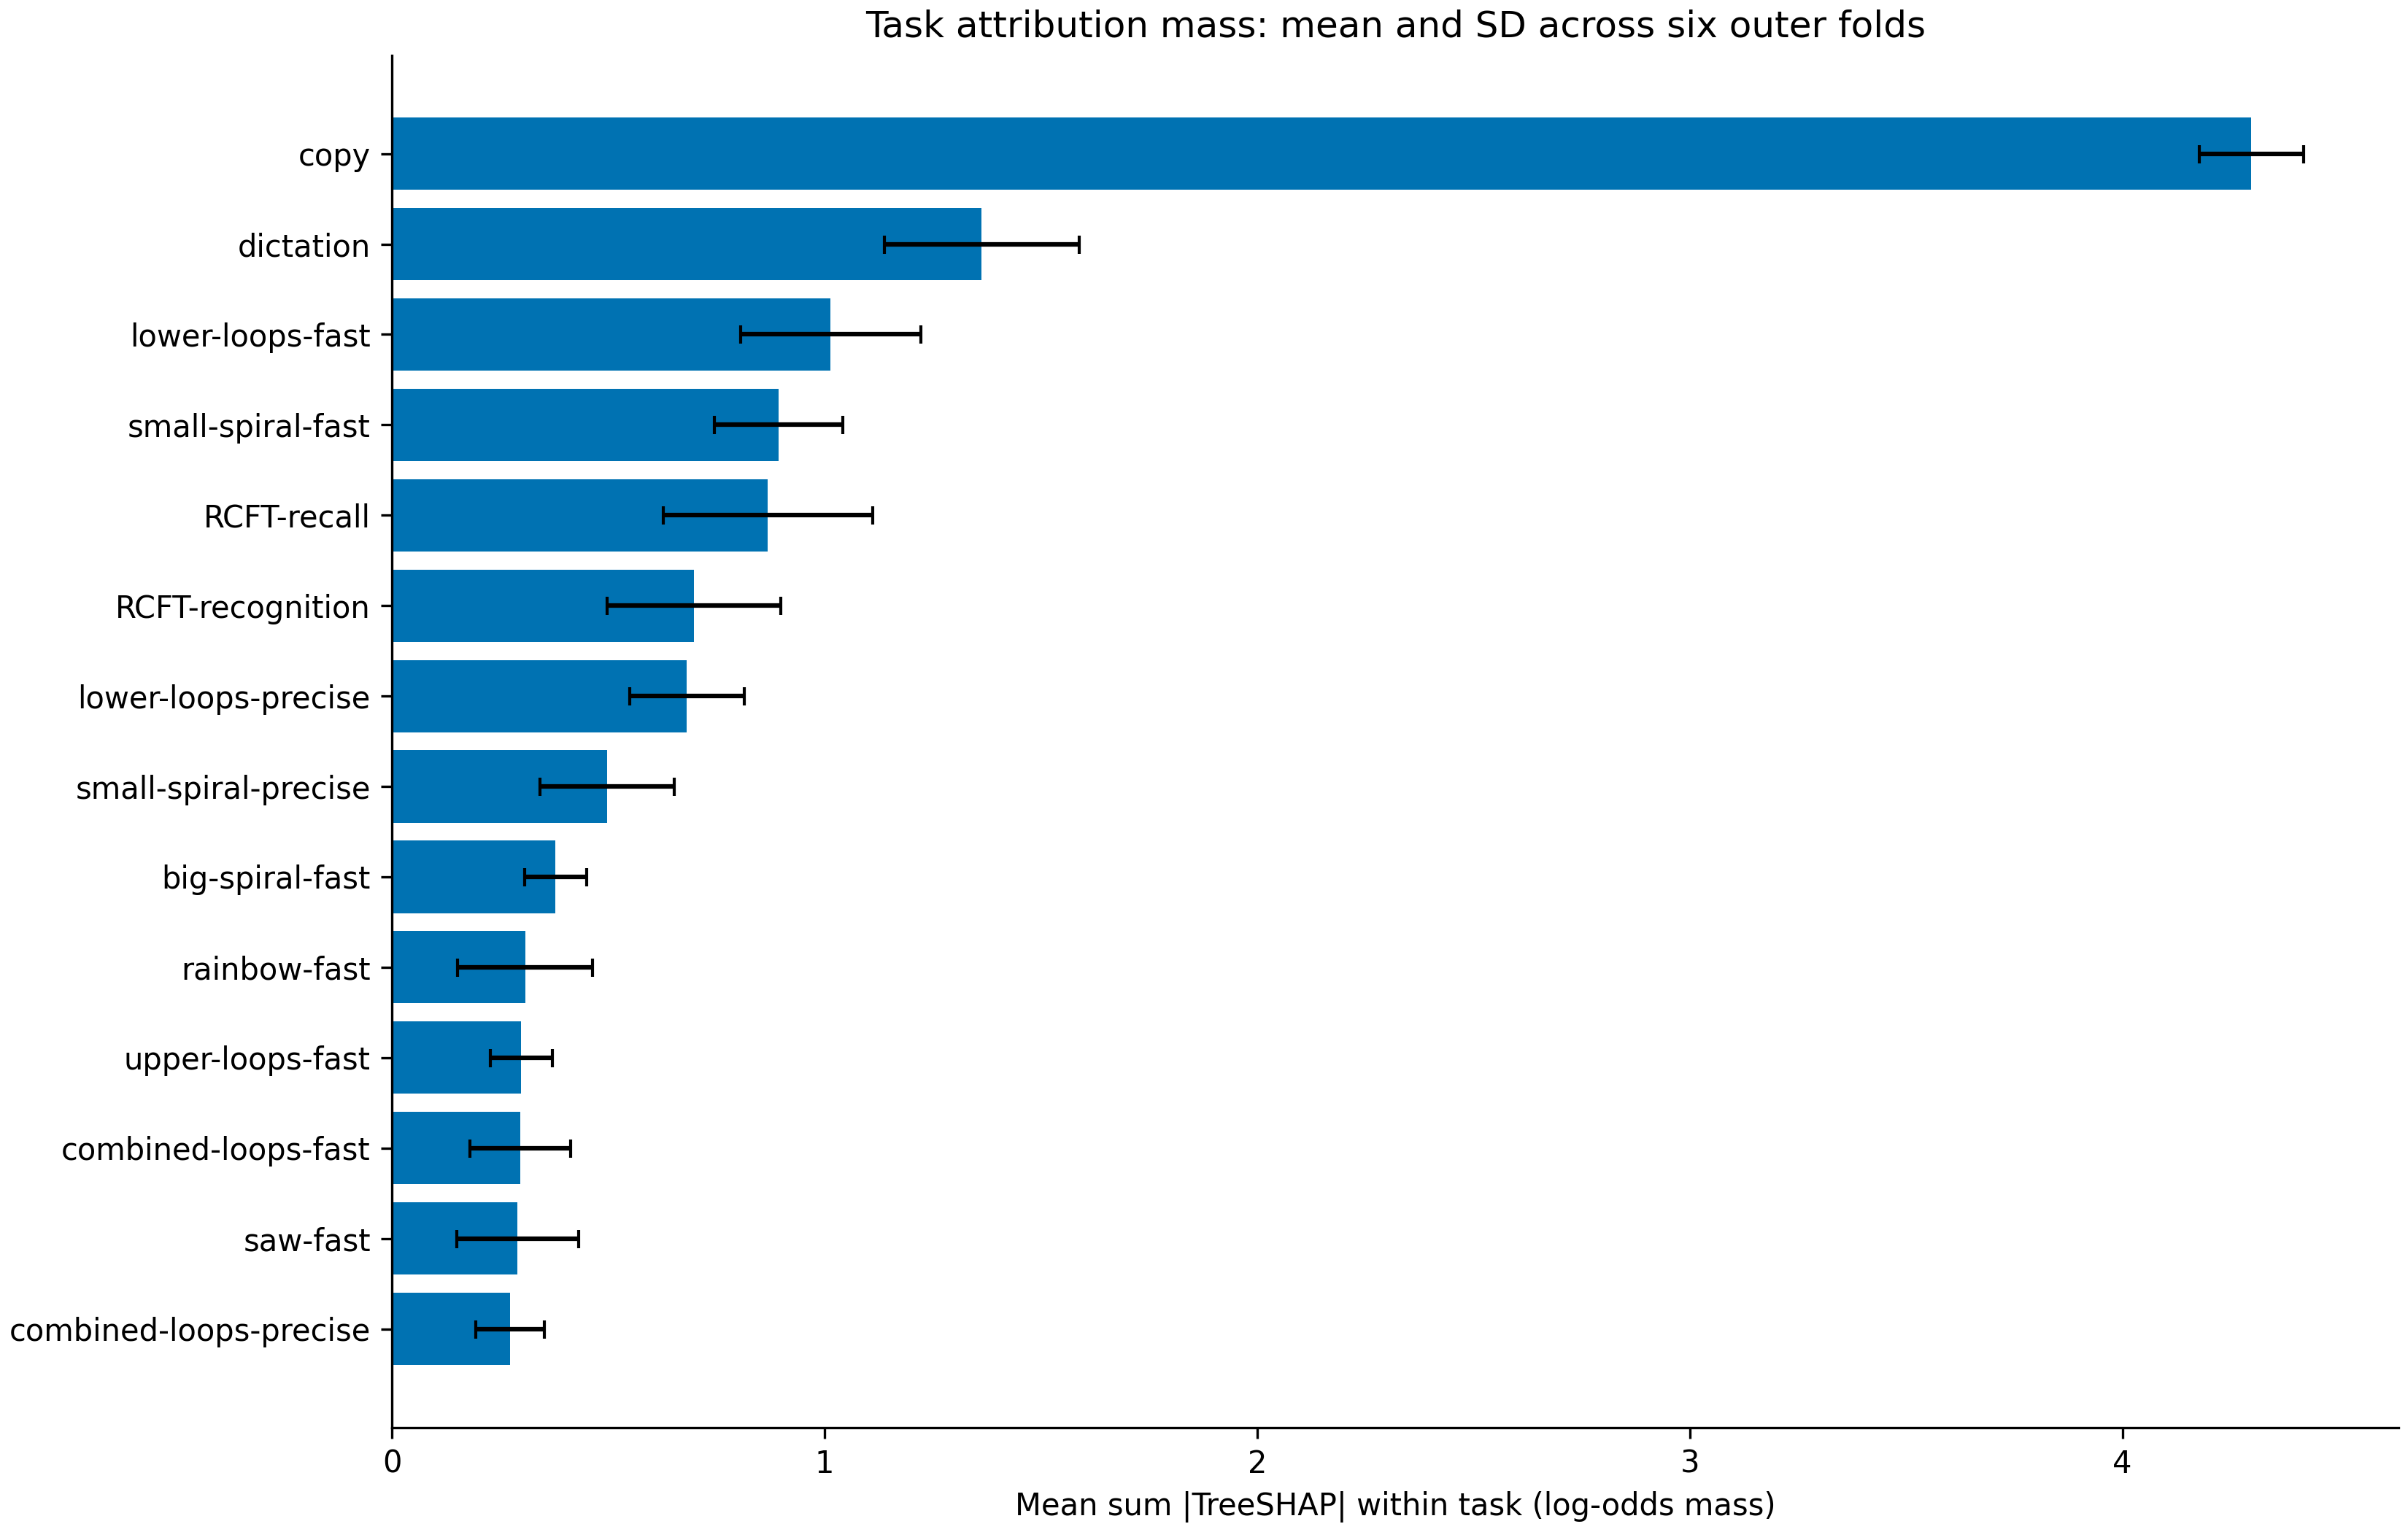

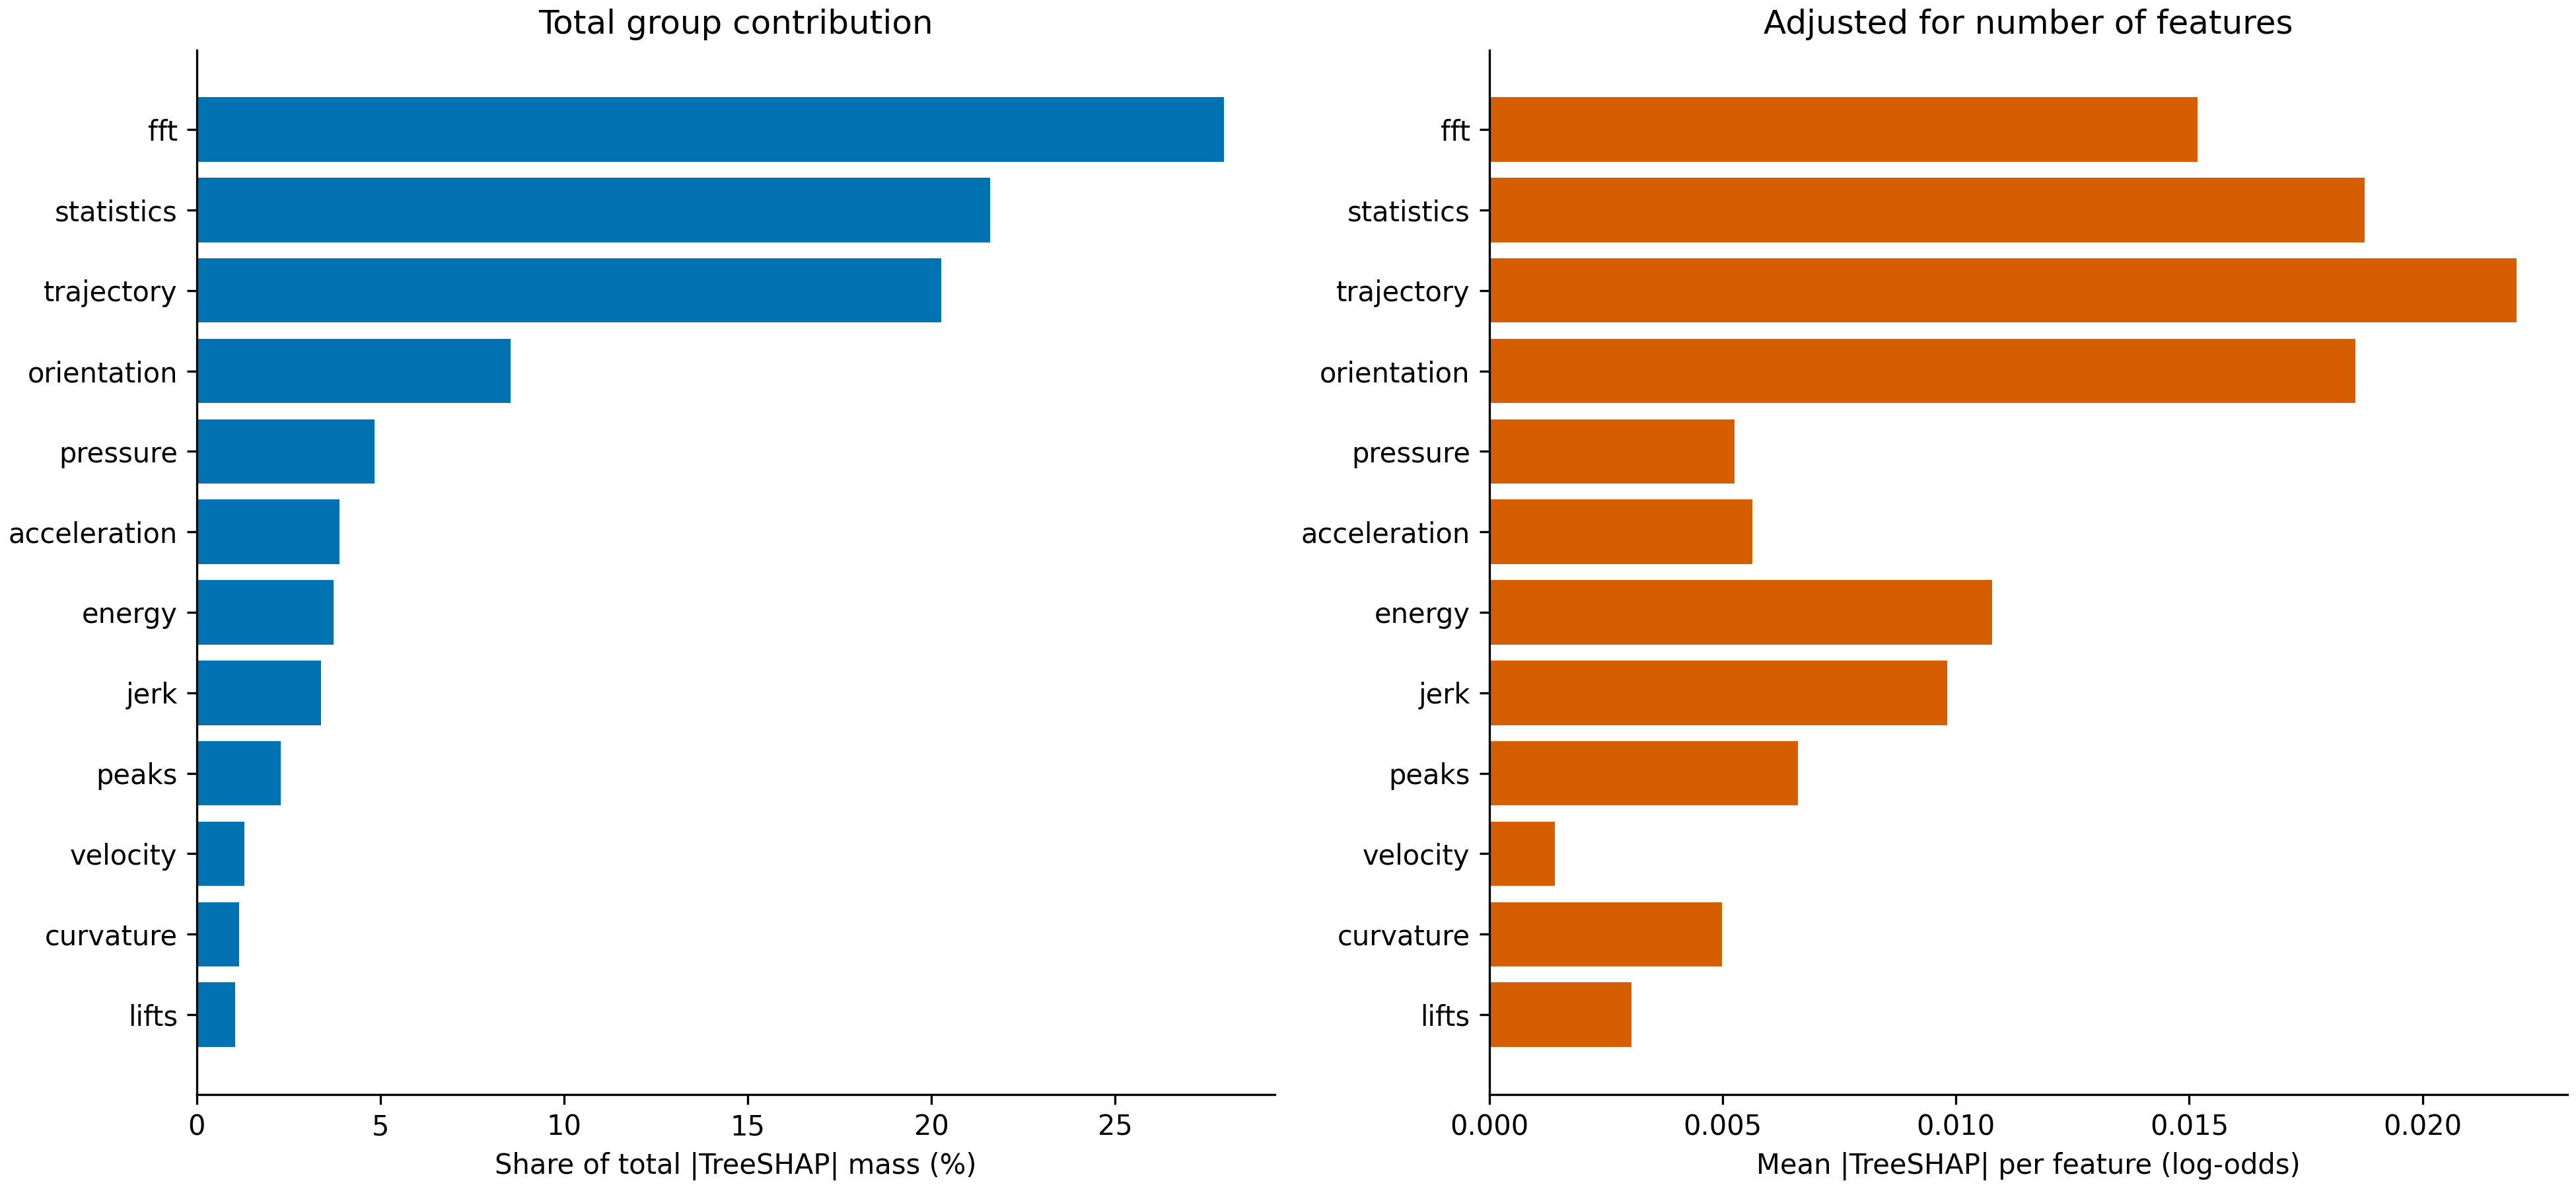

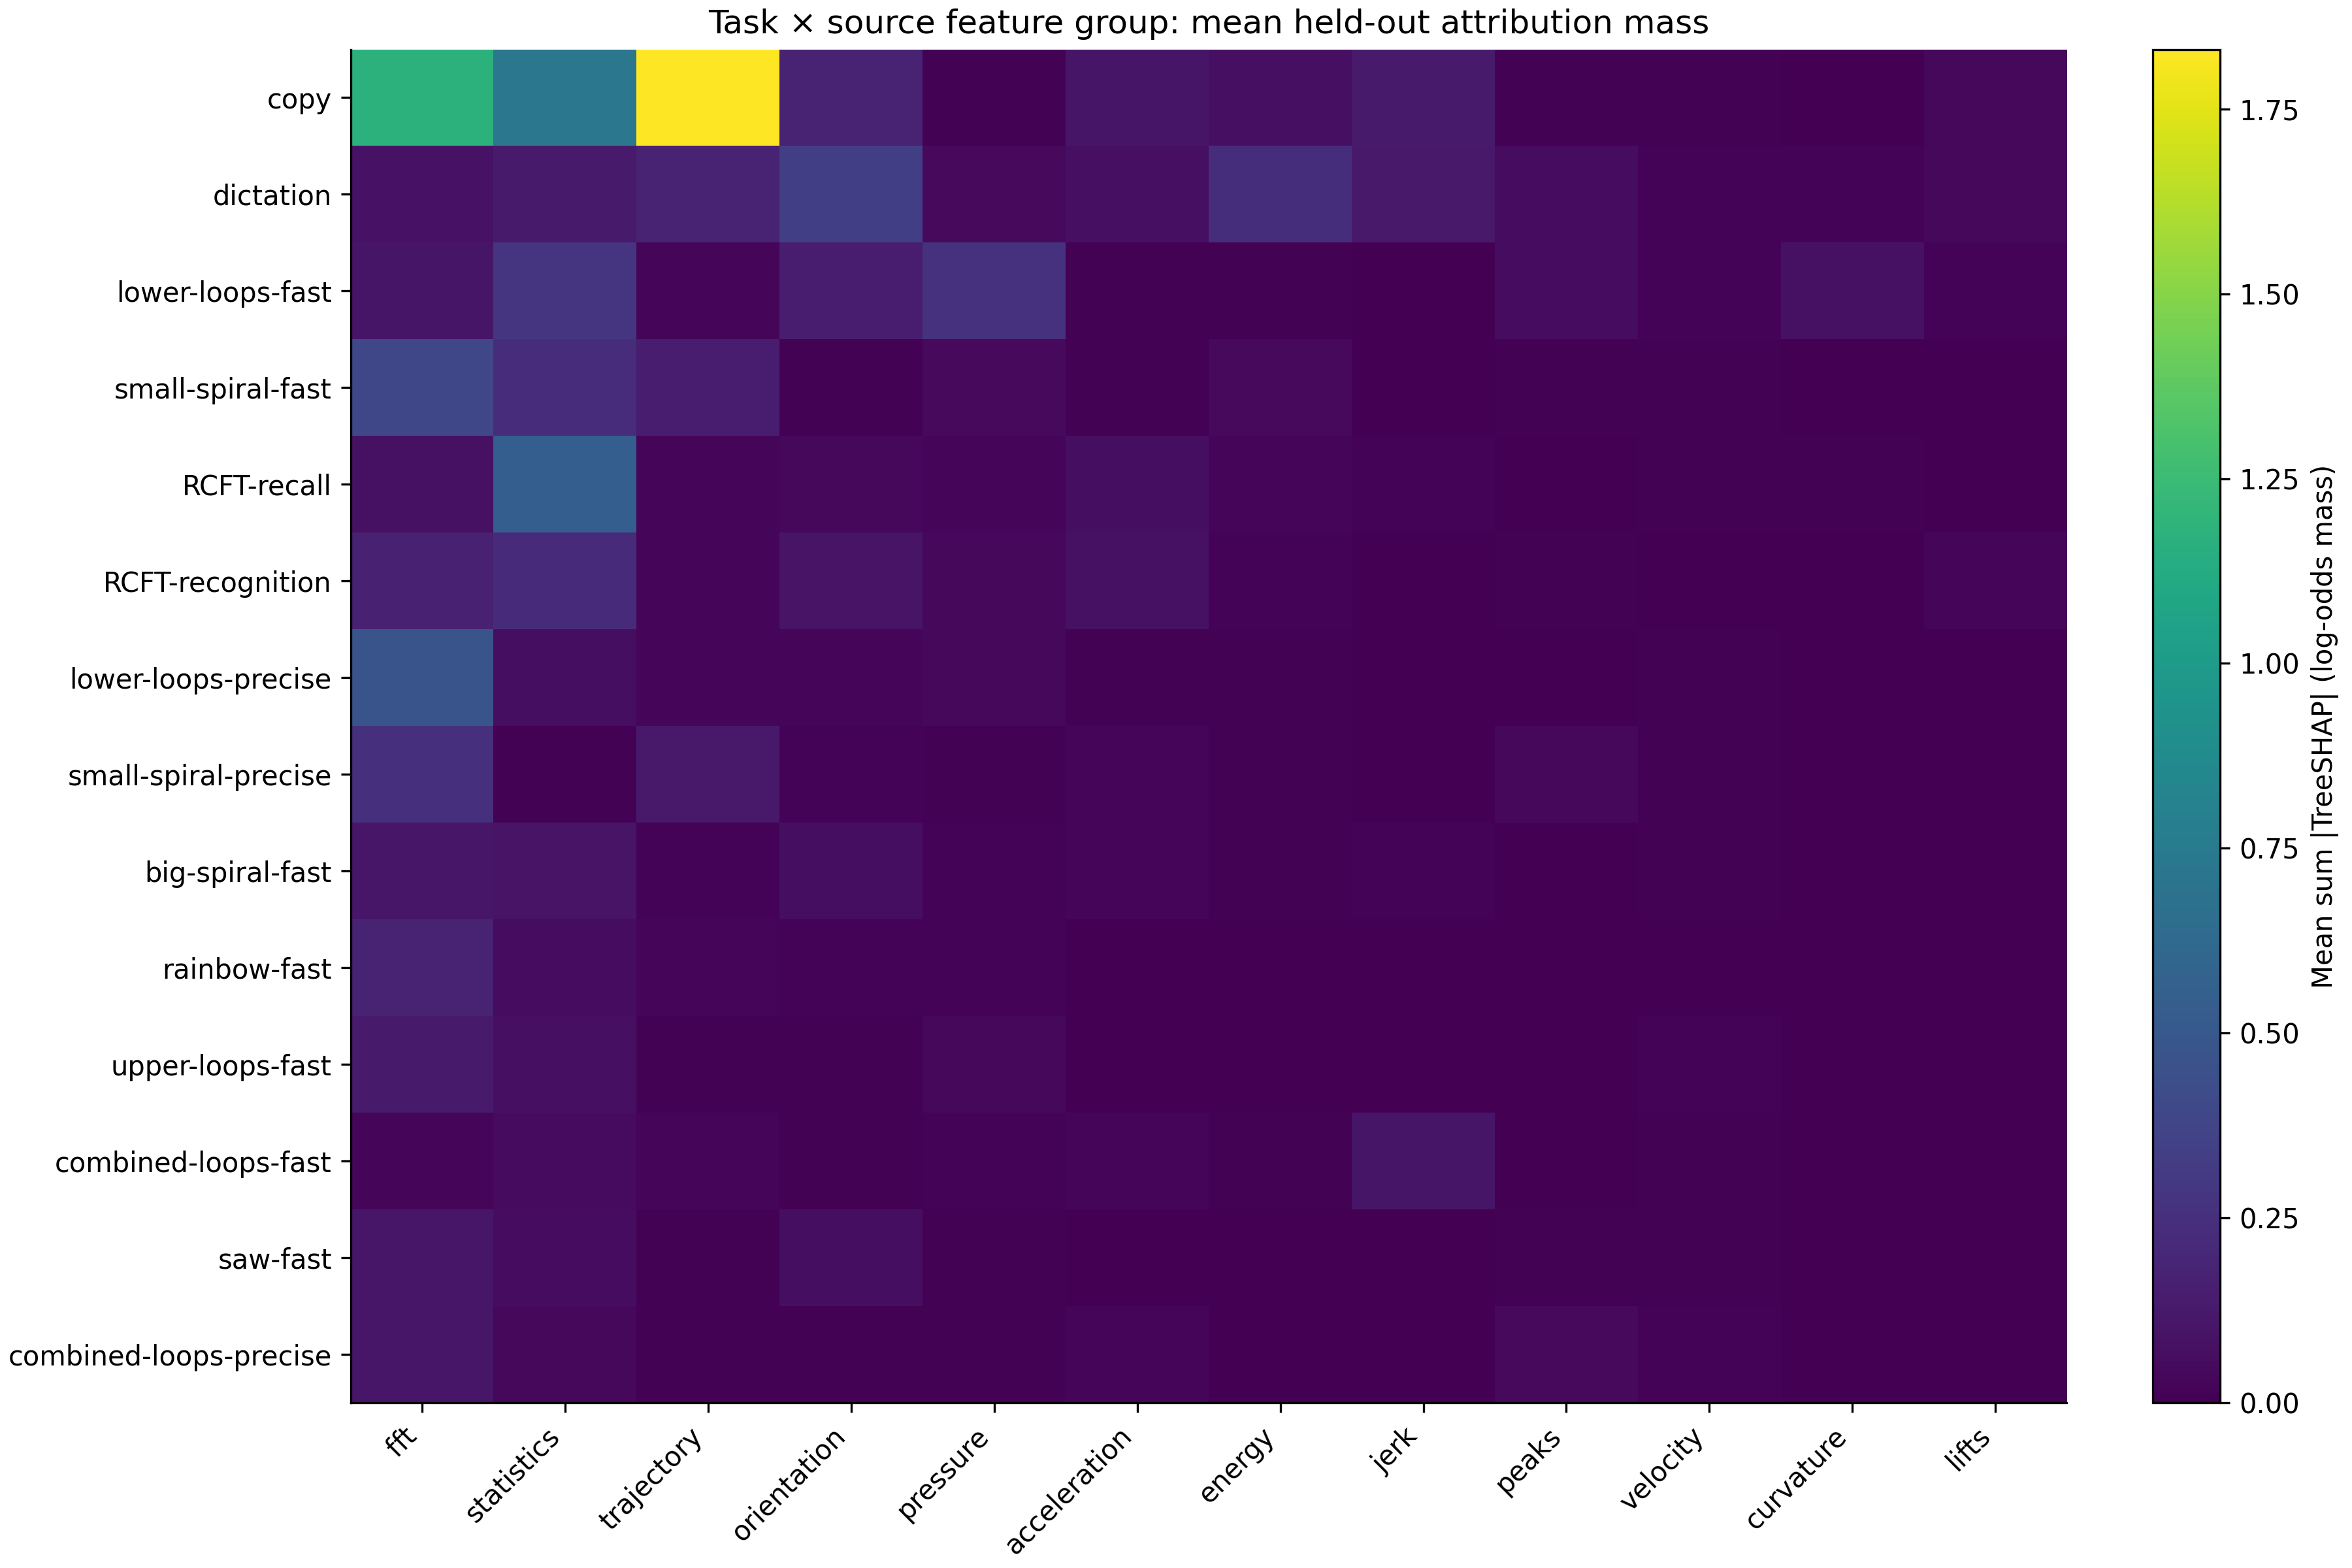

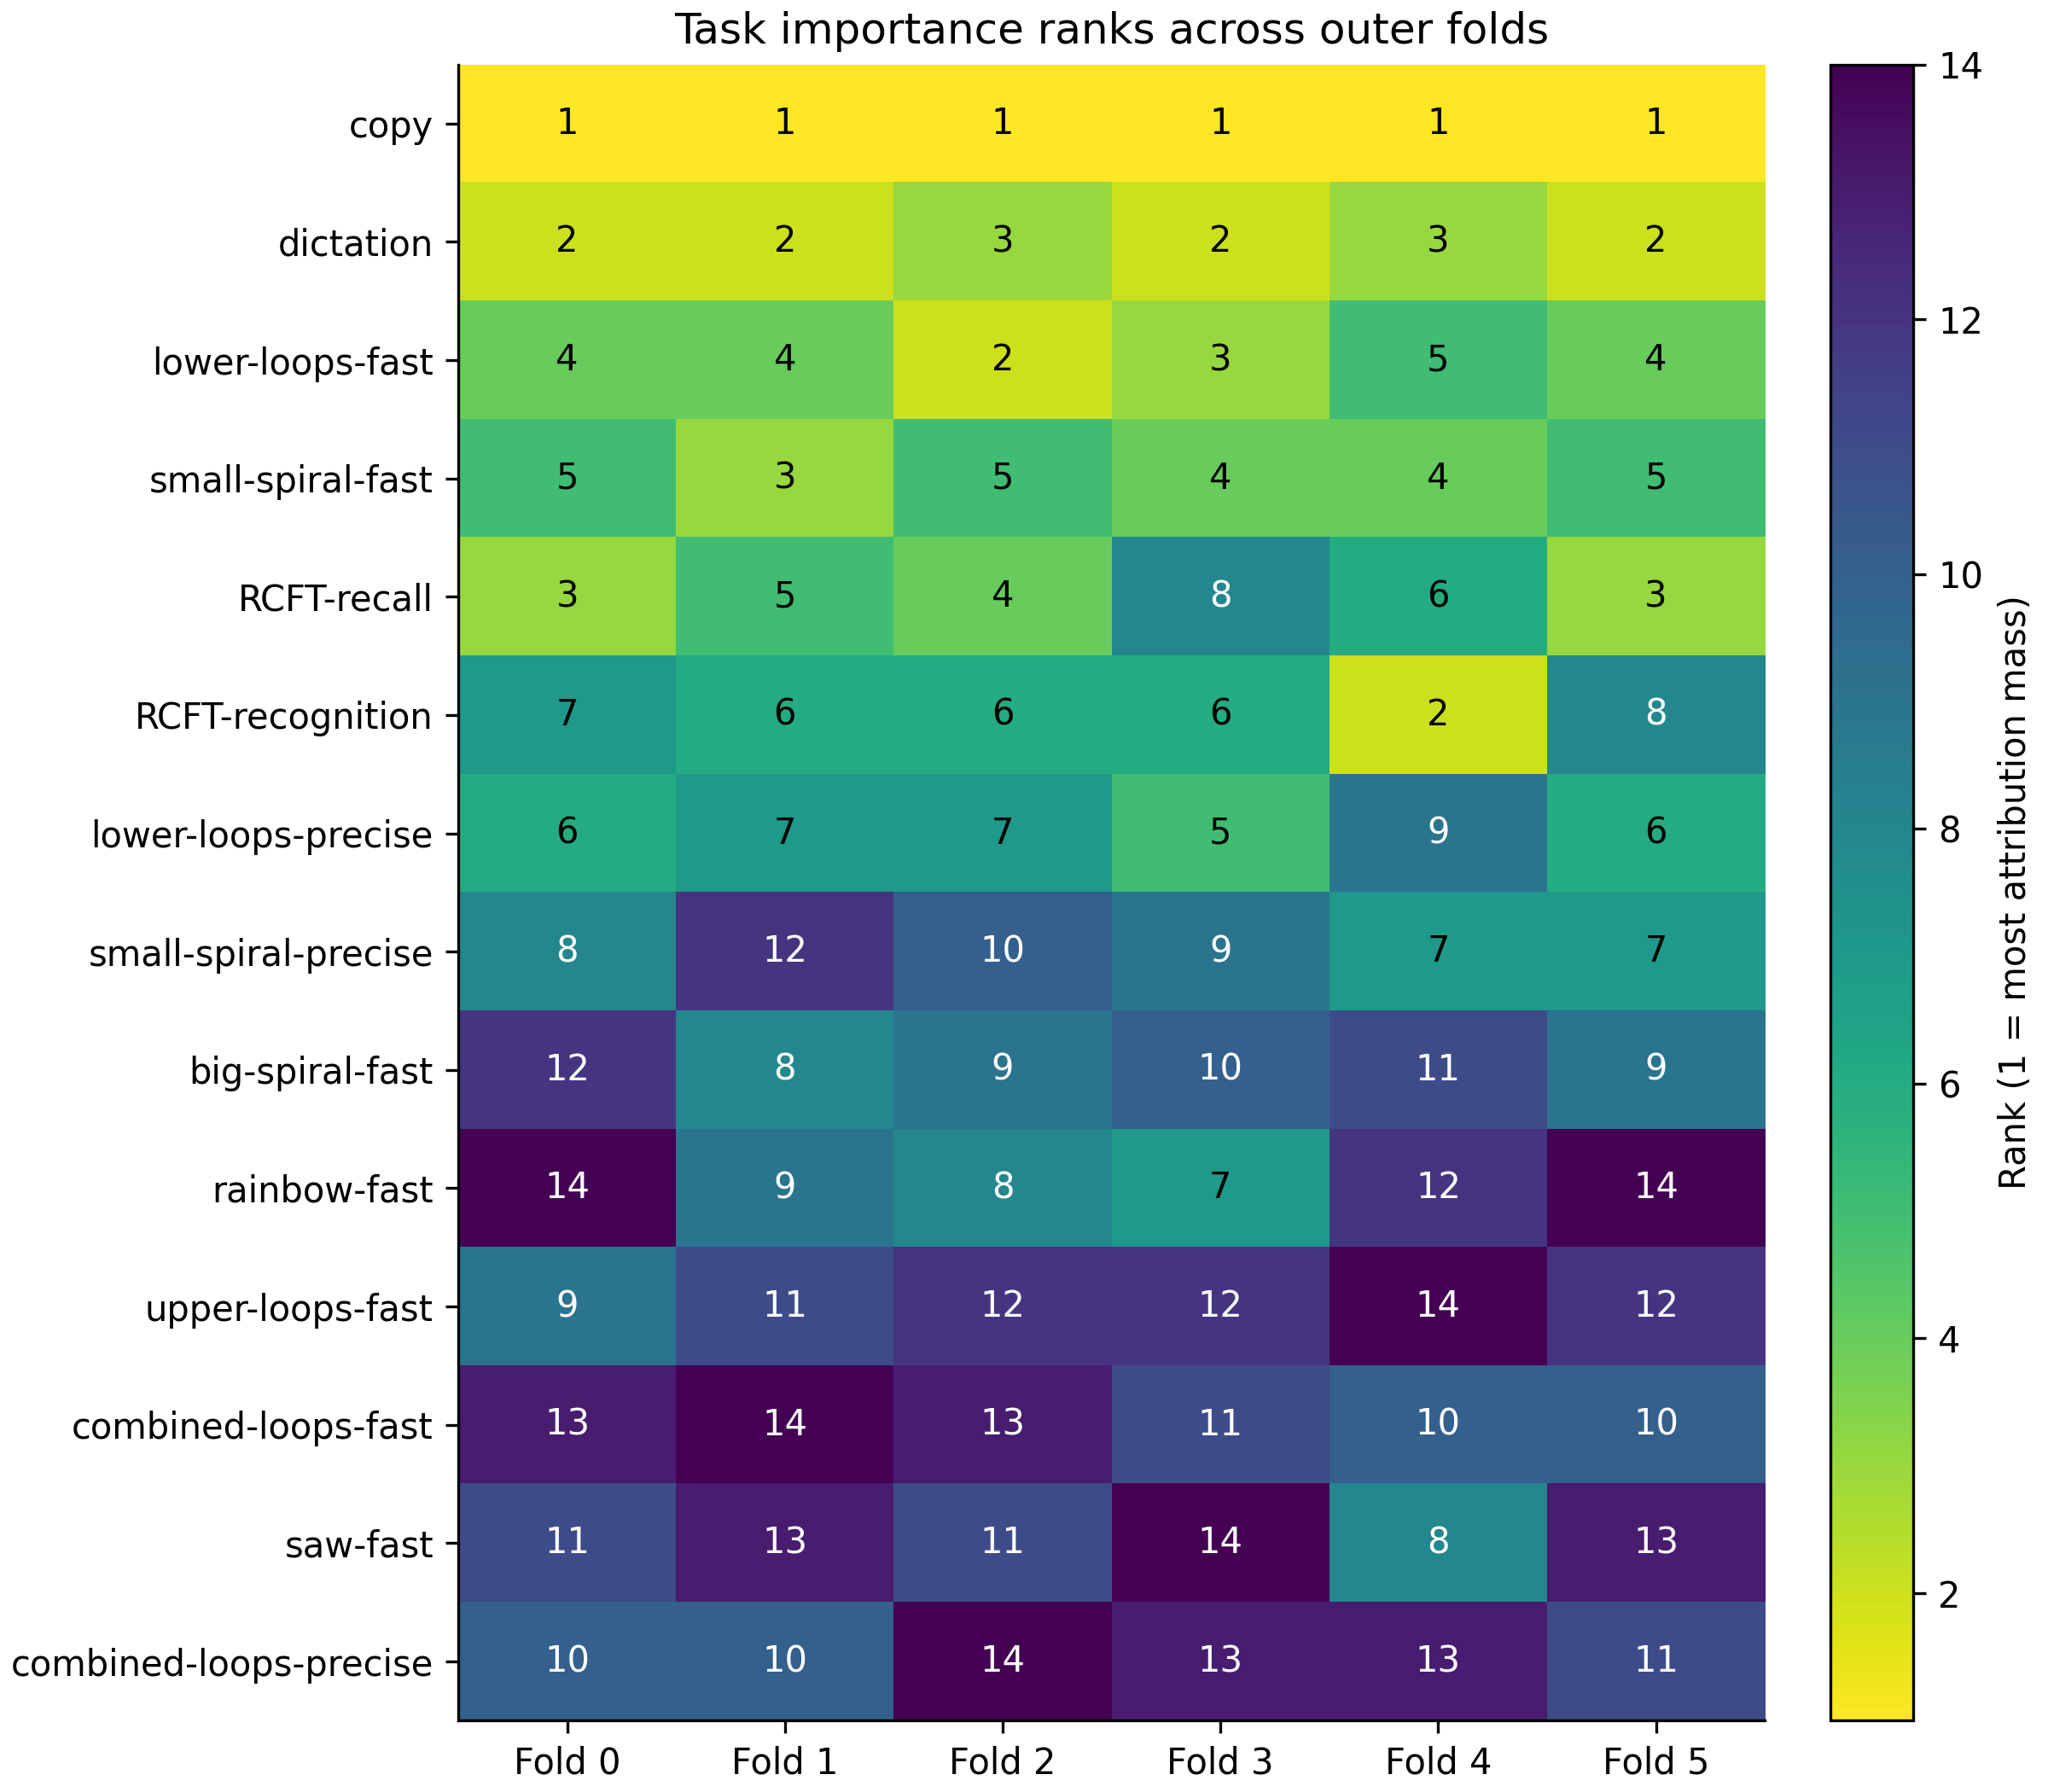

In [9]:
for name in ['shap_beeswarm','shap_bar','task_importance','feature_groups','task_group_heatmap','task_fold_ranks']:
    show(name)

## Perturbation, retraining và sự bất đồng giữa các phương pháp

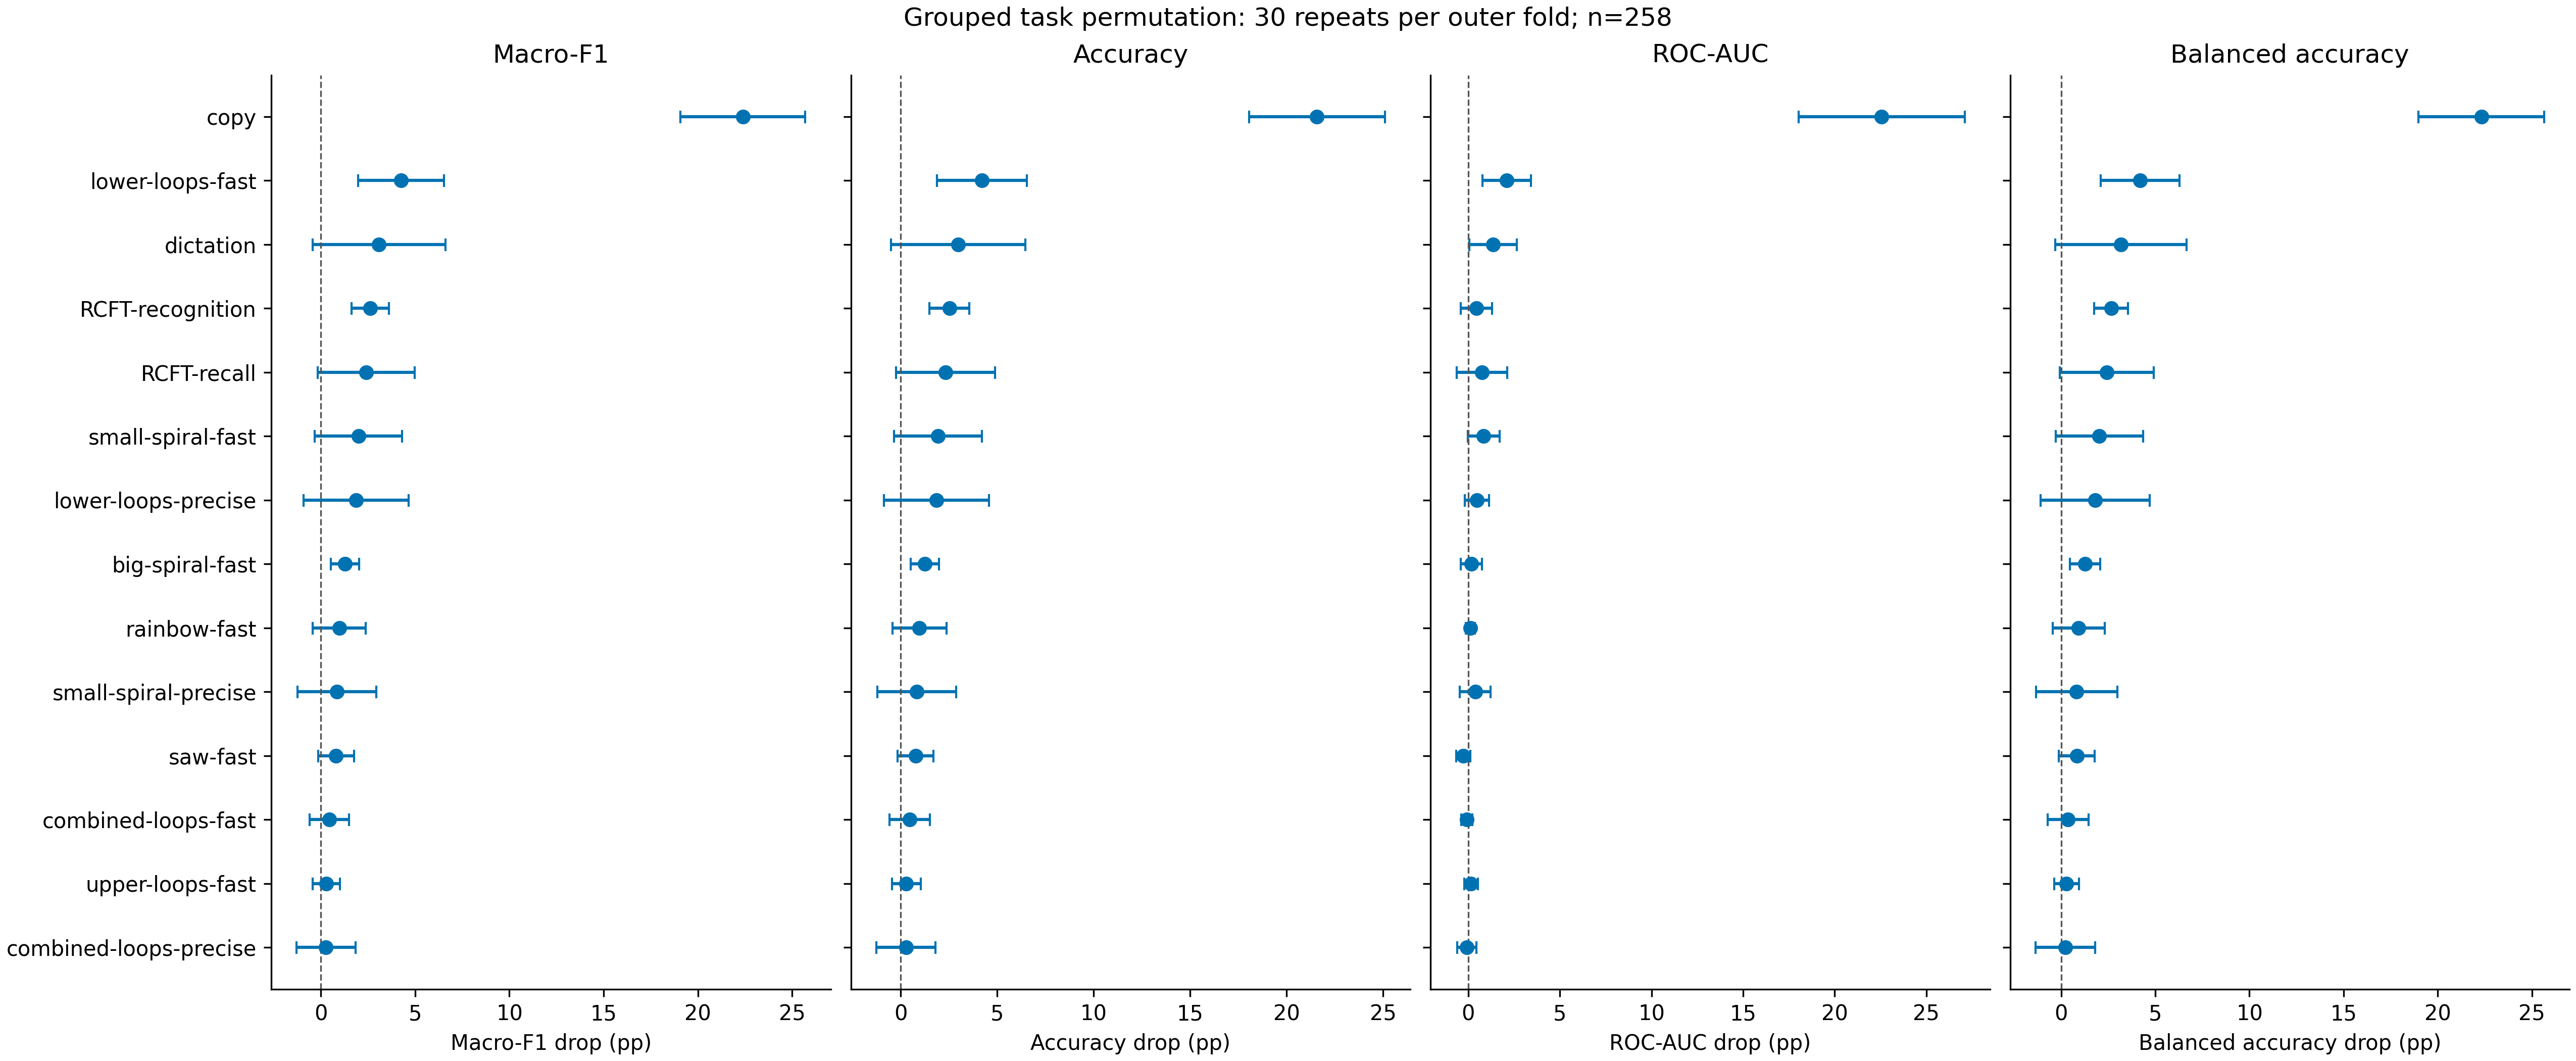

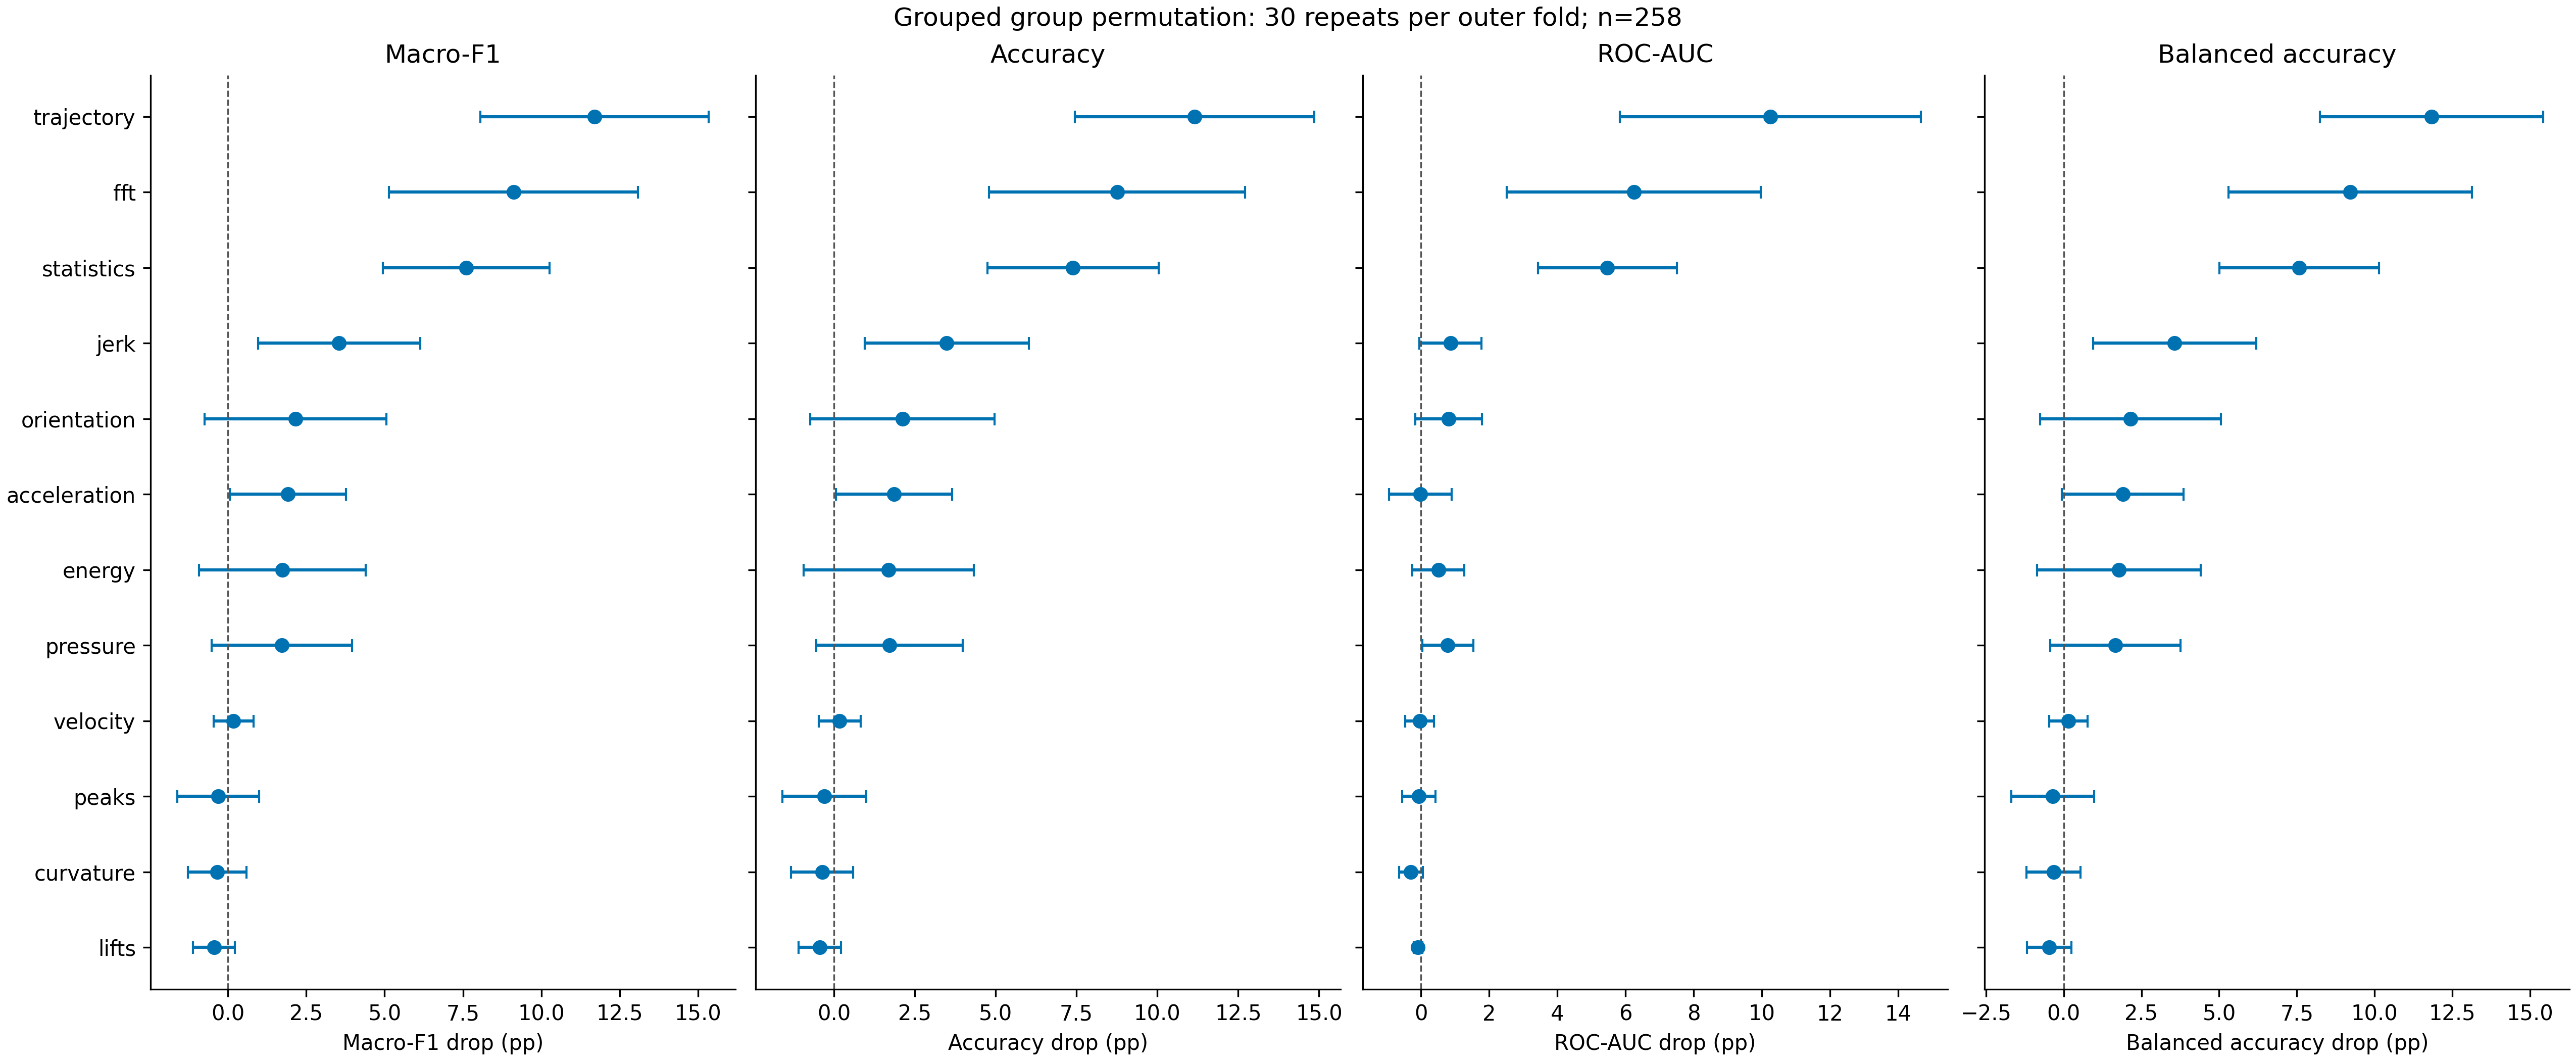

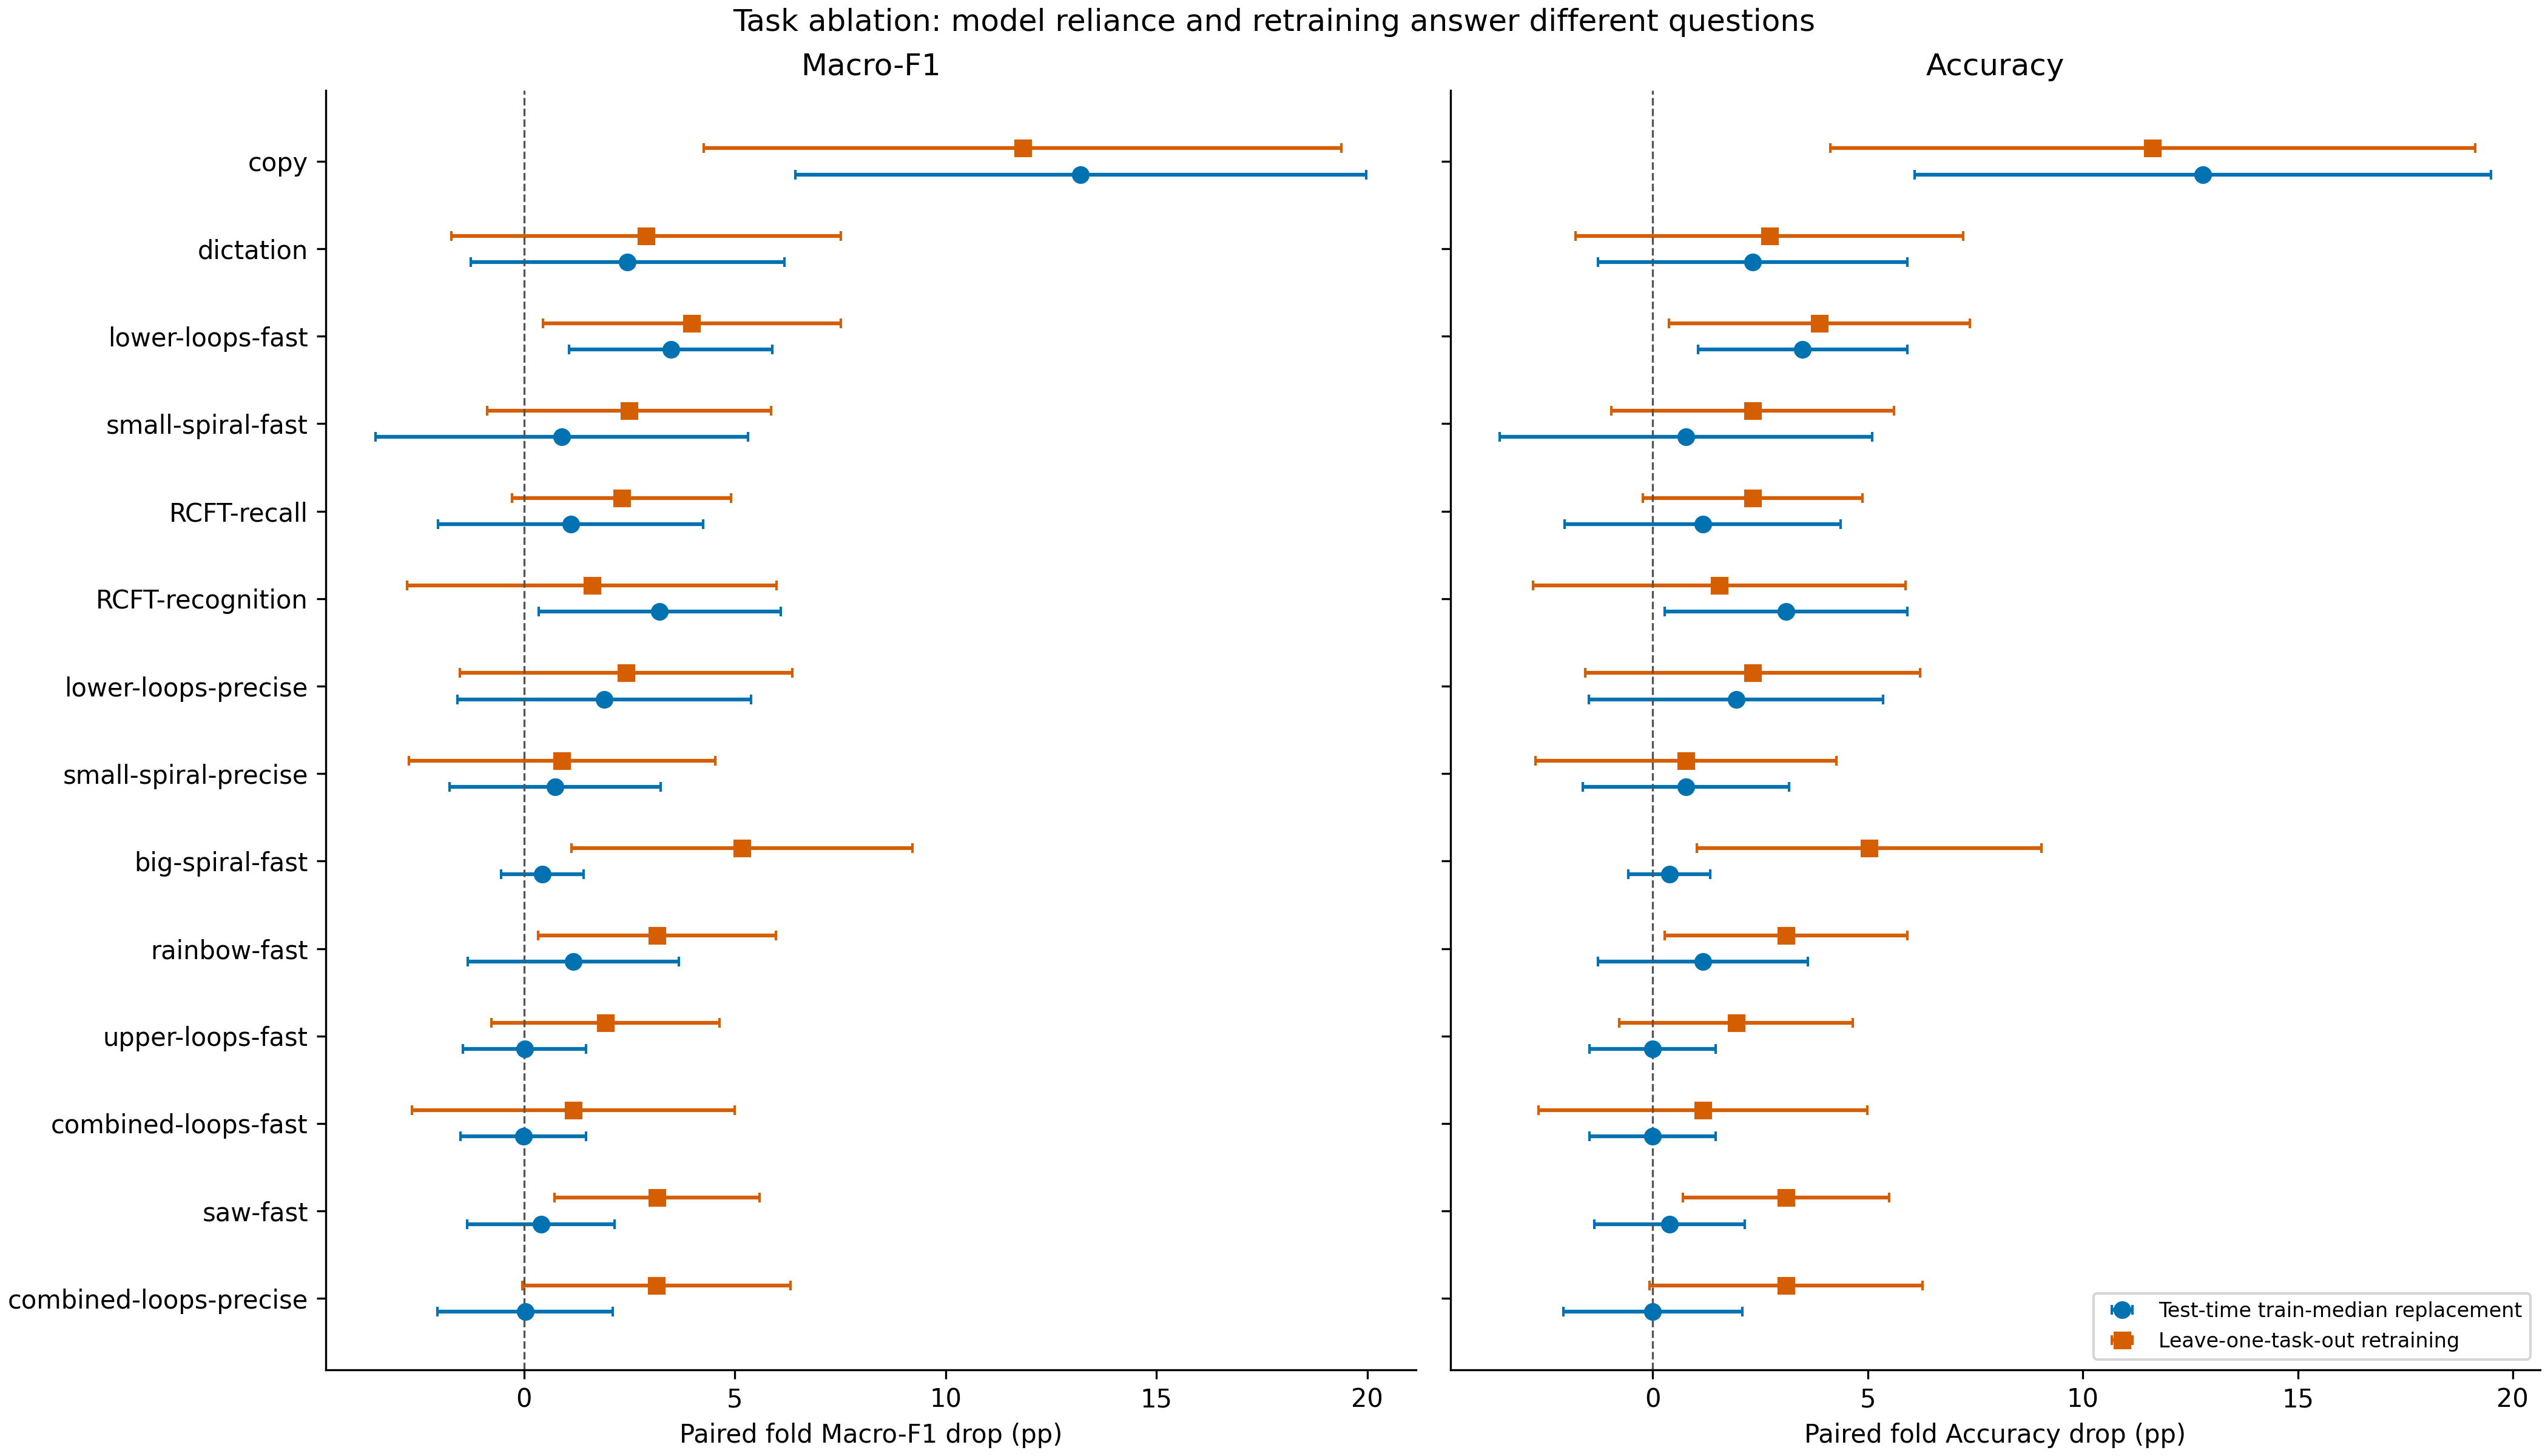

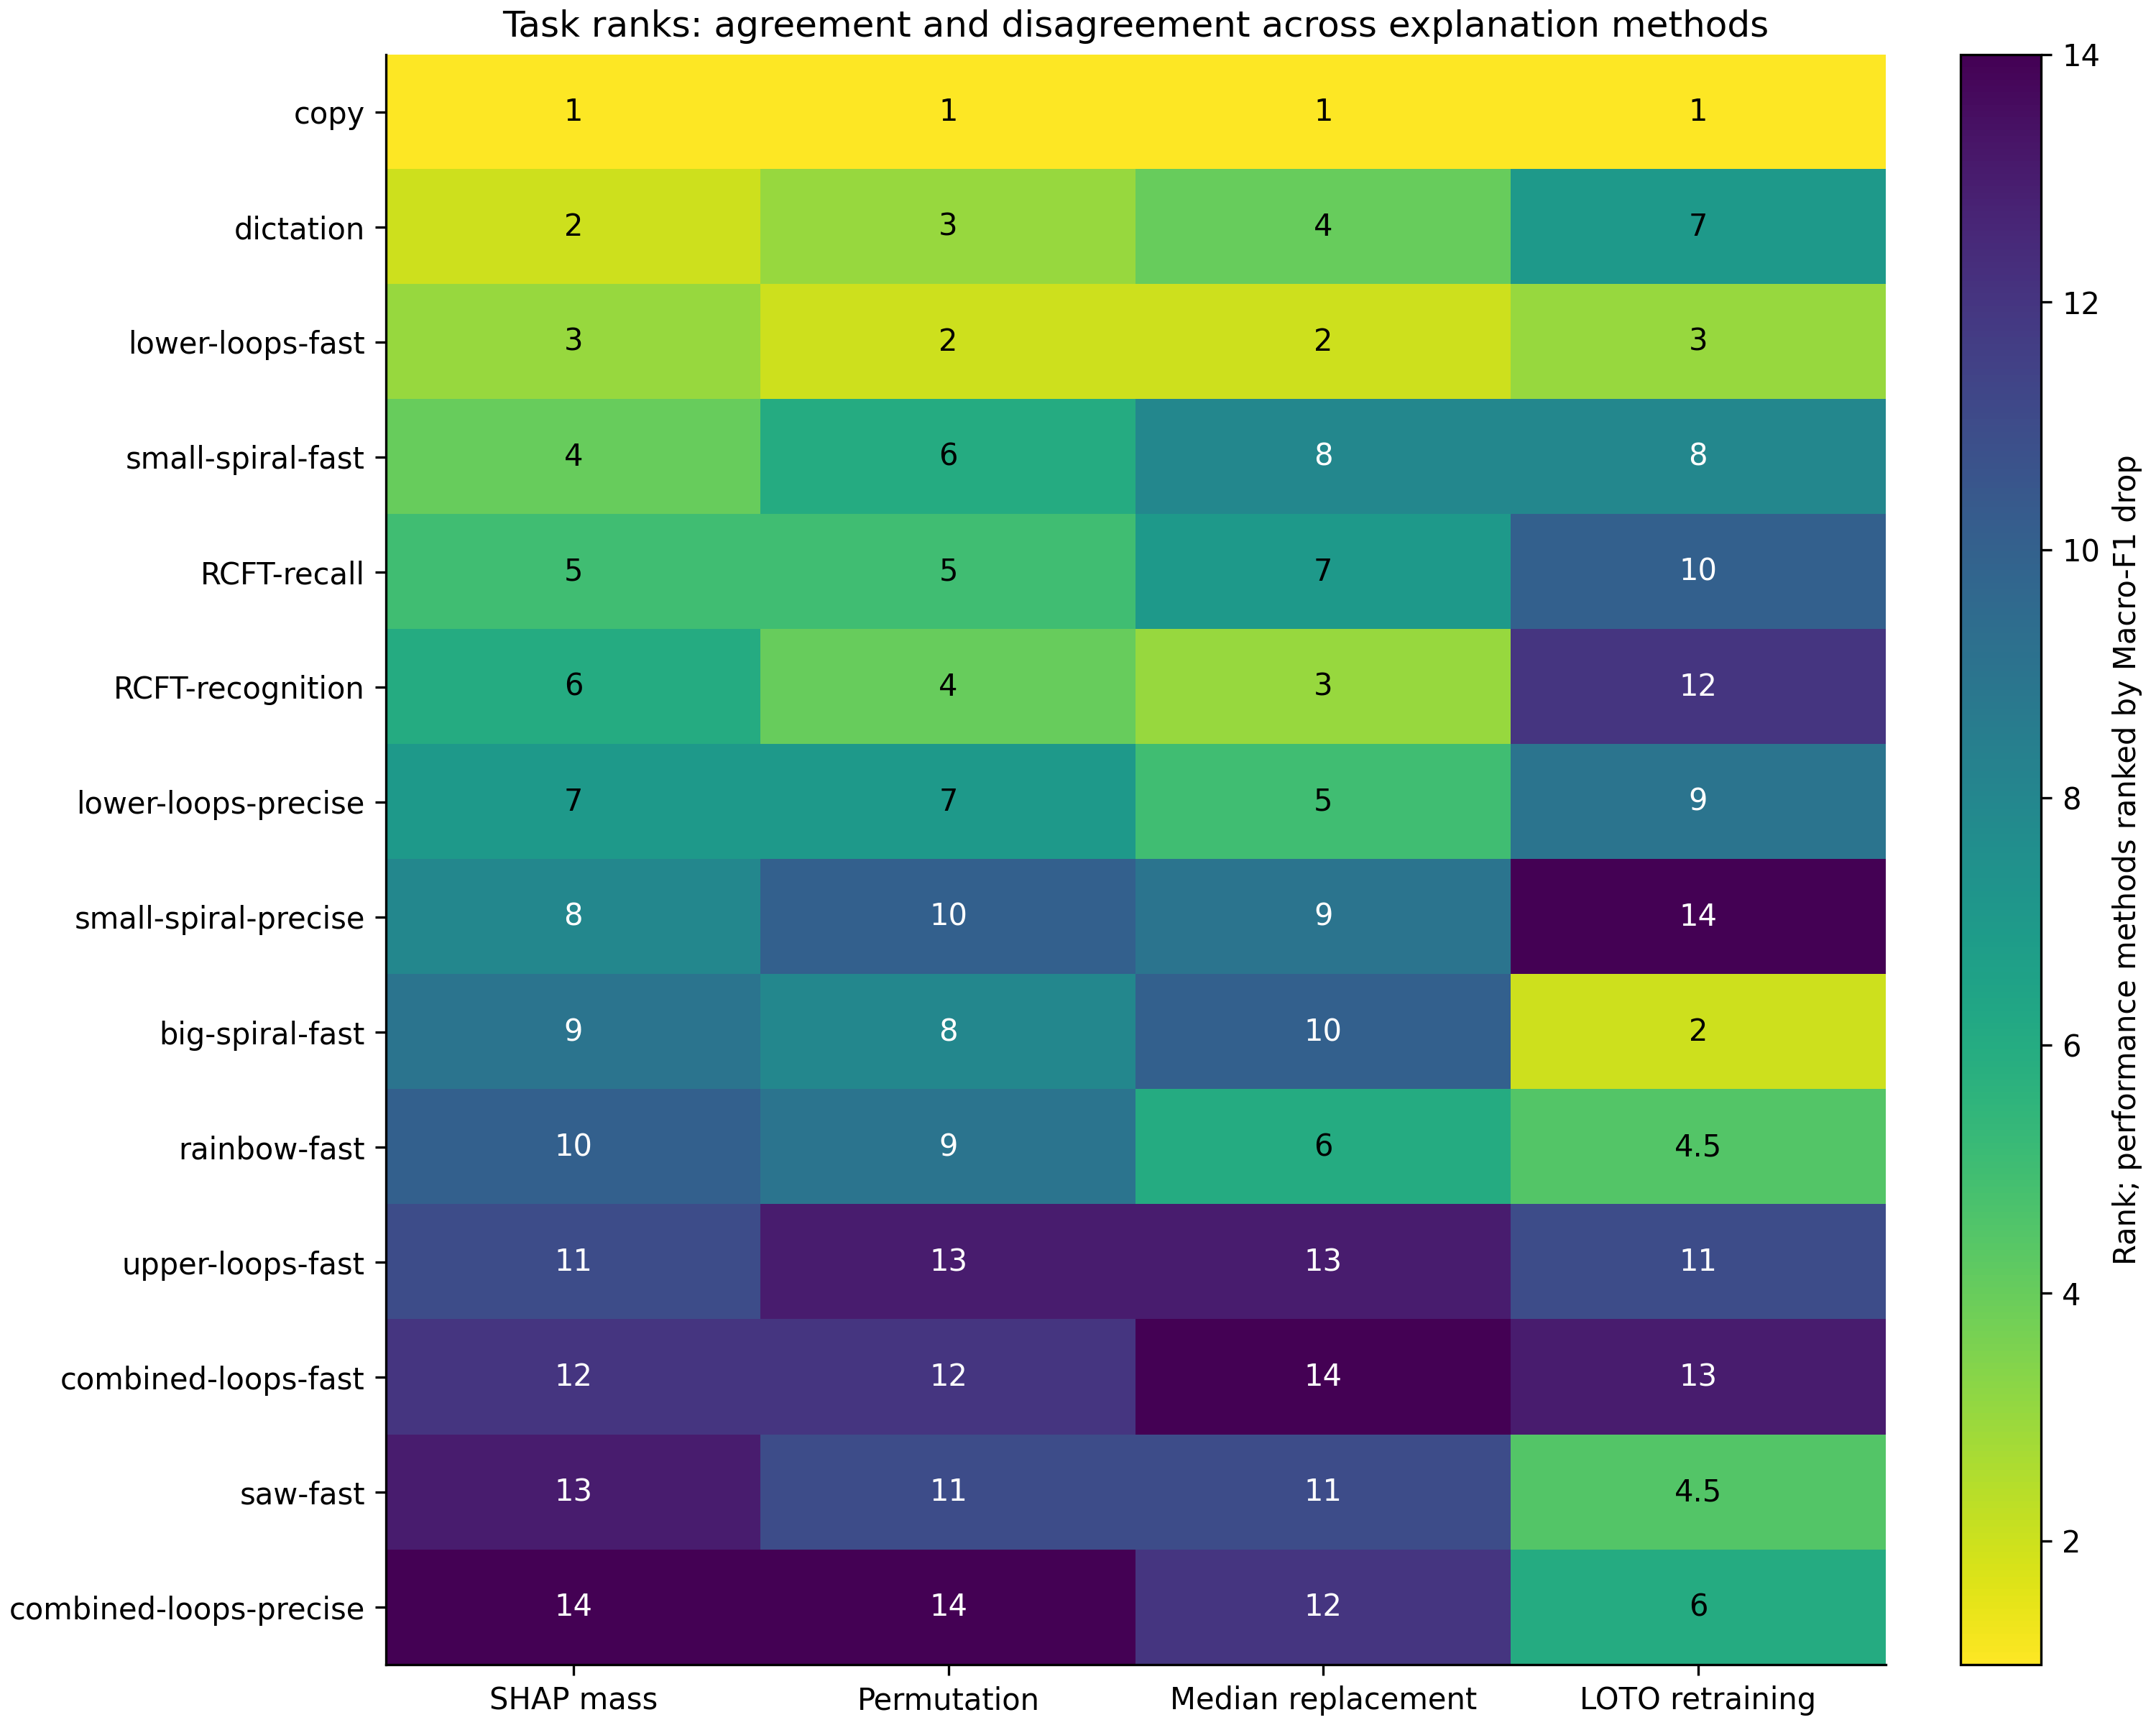

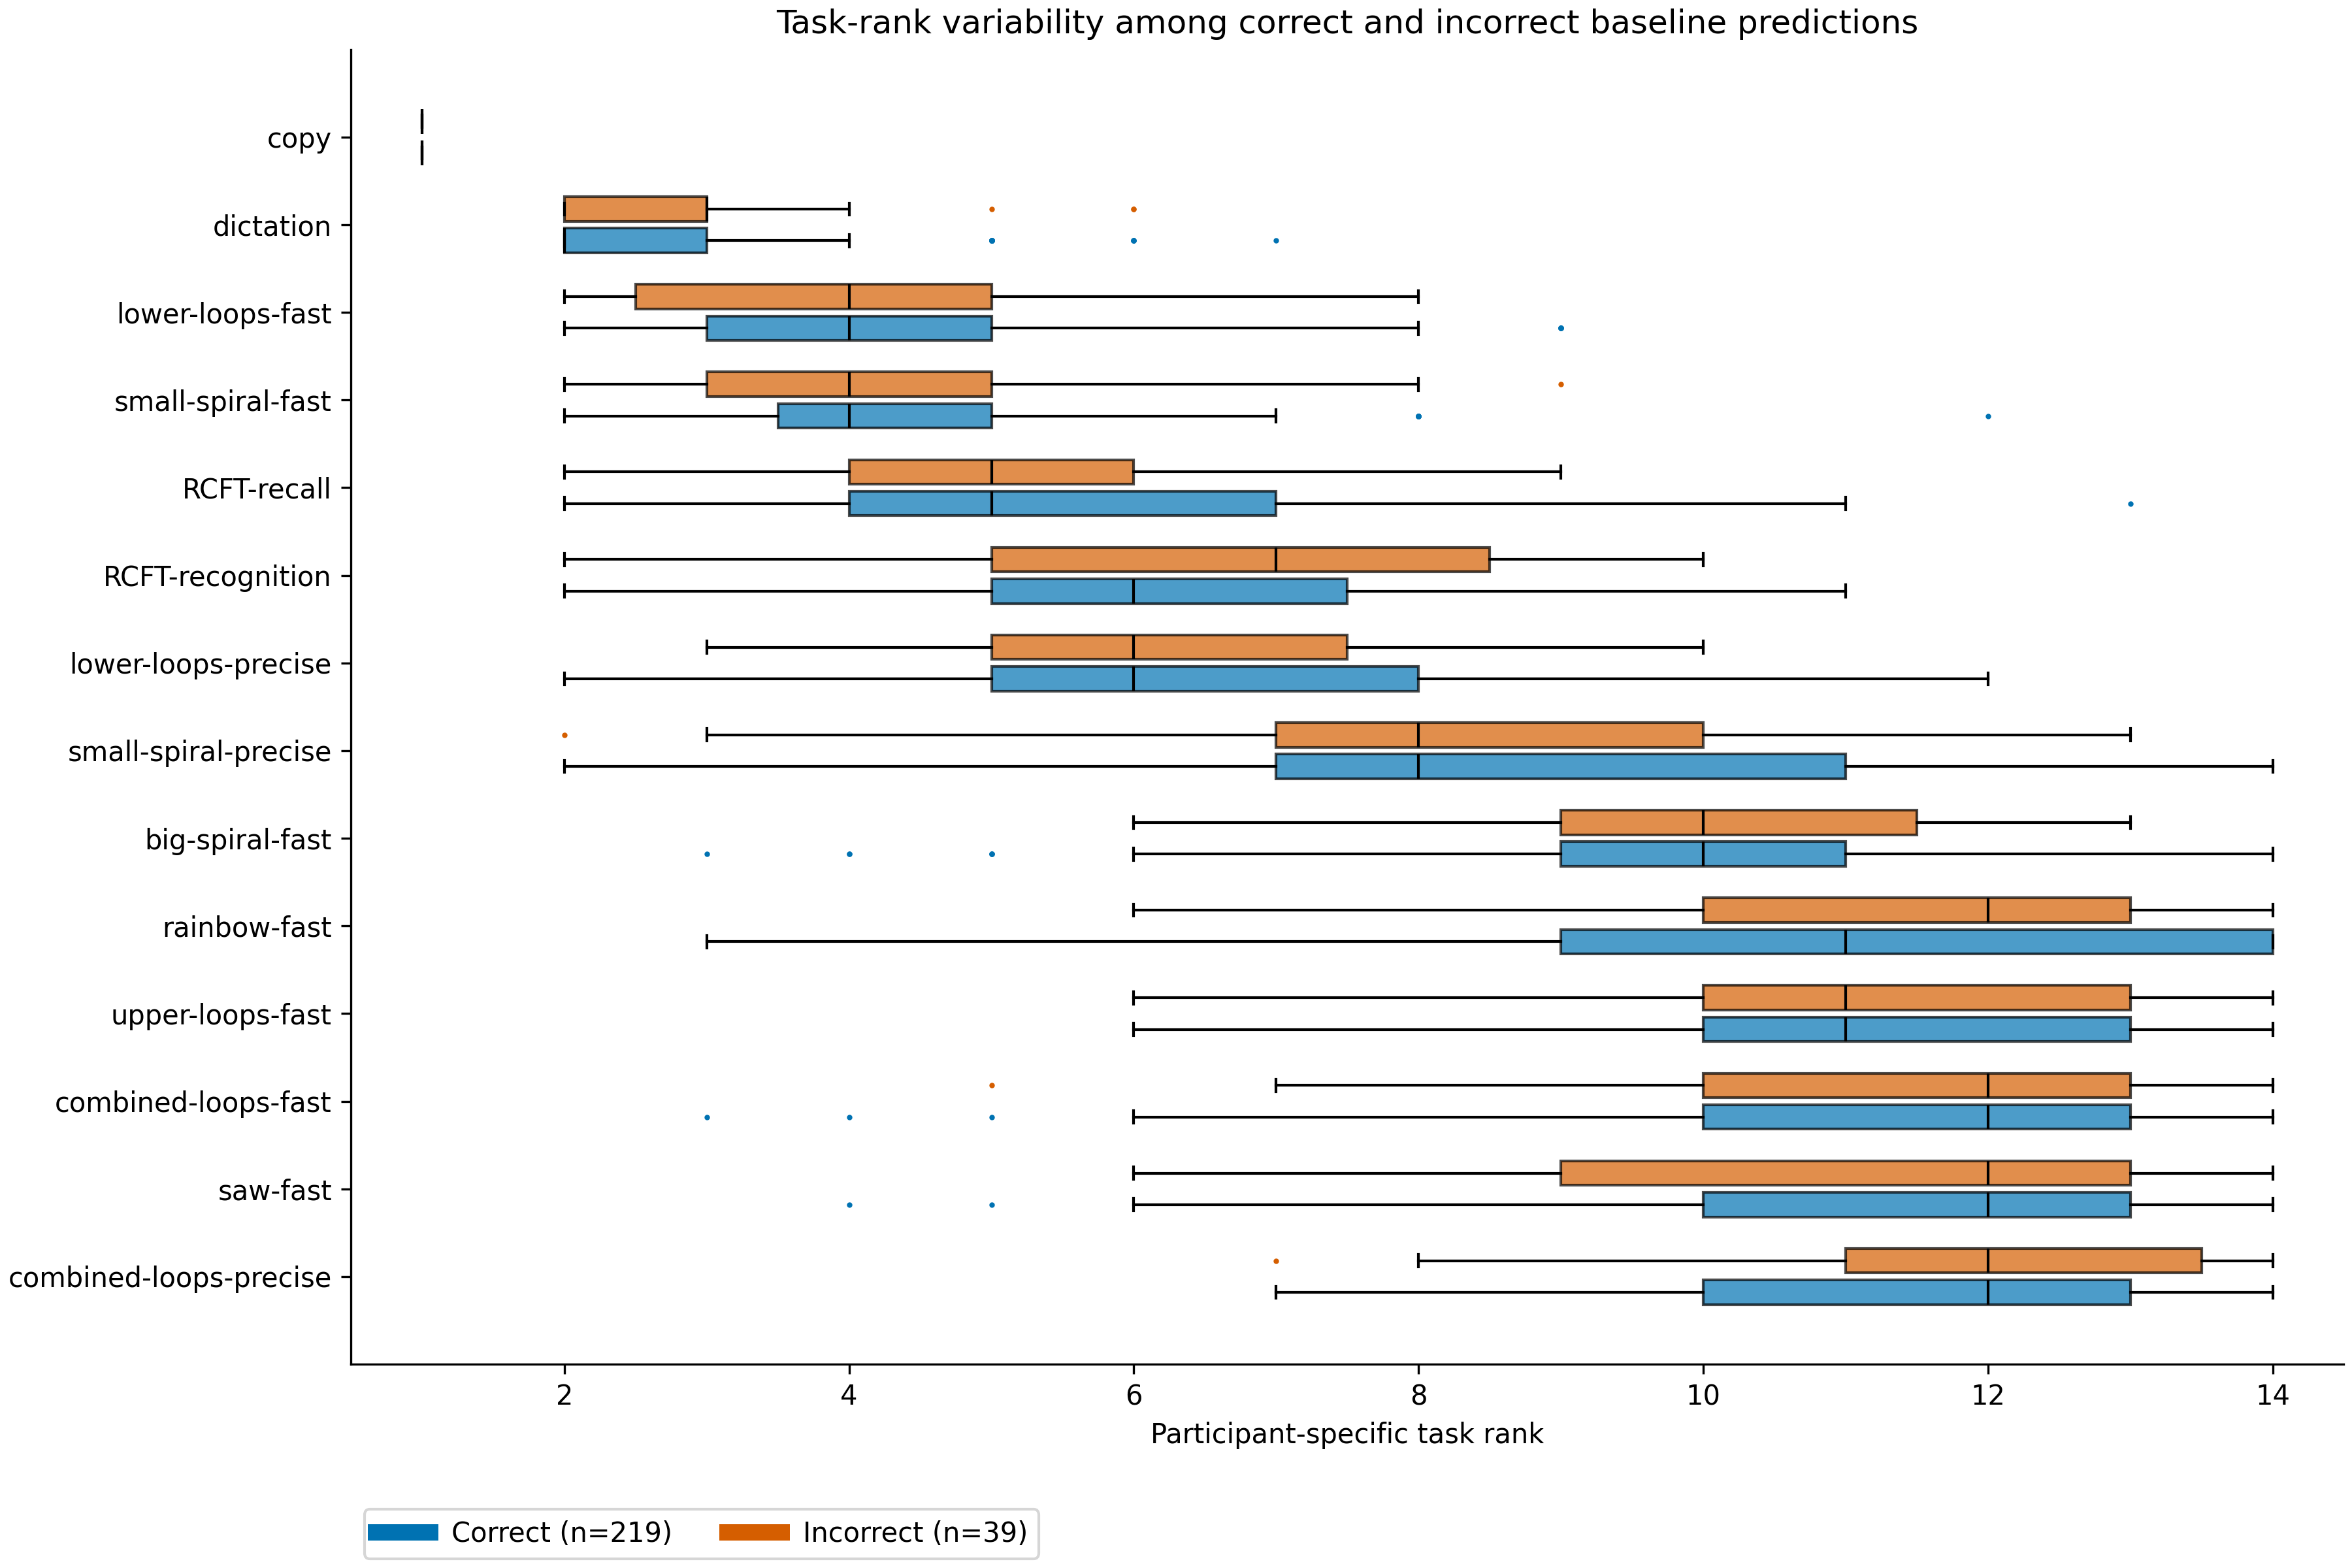

In [10]:
for name in ['permutation_task','permutation_group','task_ablation','method_rank_agreement','participant_rank_variability']:
    show(name)

## Local explanations
ID đầu tiên theo thứ tự từ điển trong từng outcome baseline; lựa chọn hậu kiểm để minh họa. Waterfall cộng trong raw log-odds, p(group=1) chỉ là kết quả sigmoid sau khi cộng.

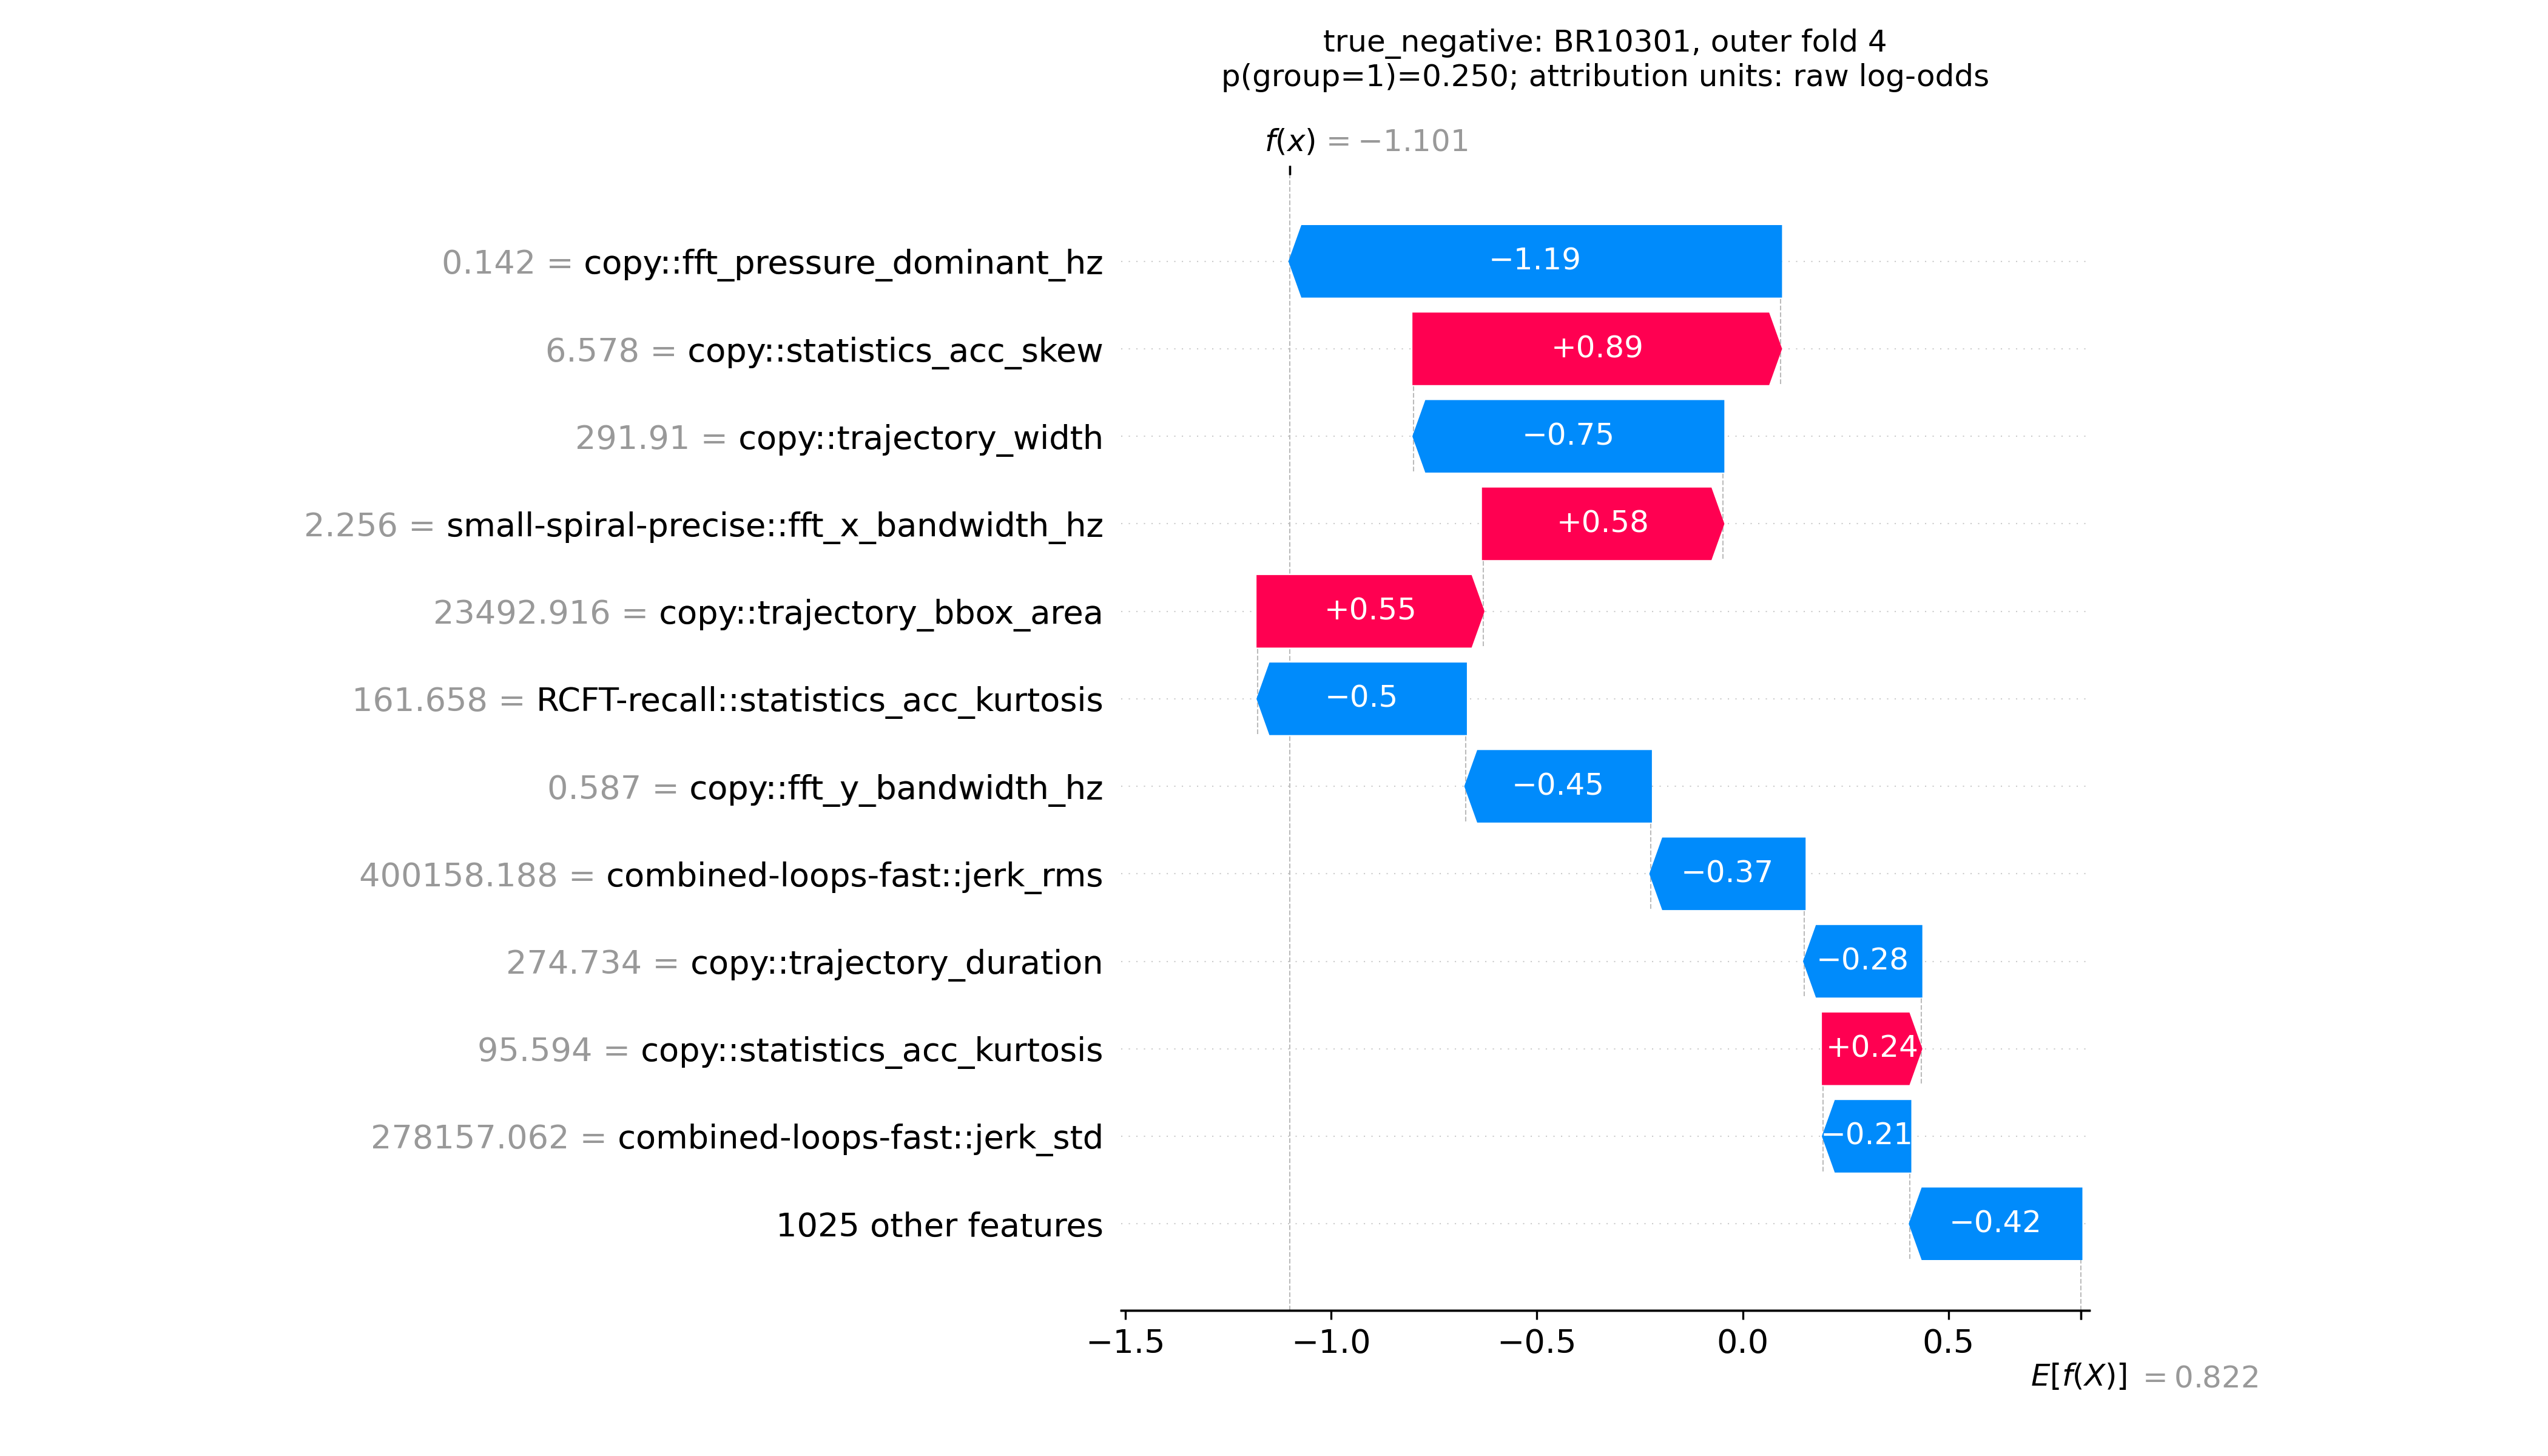

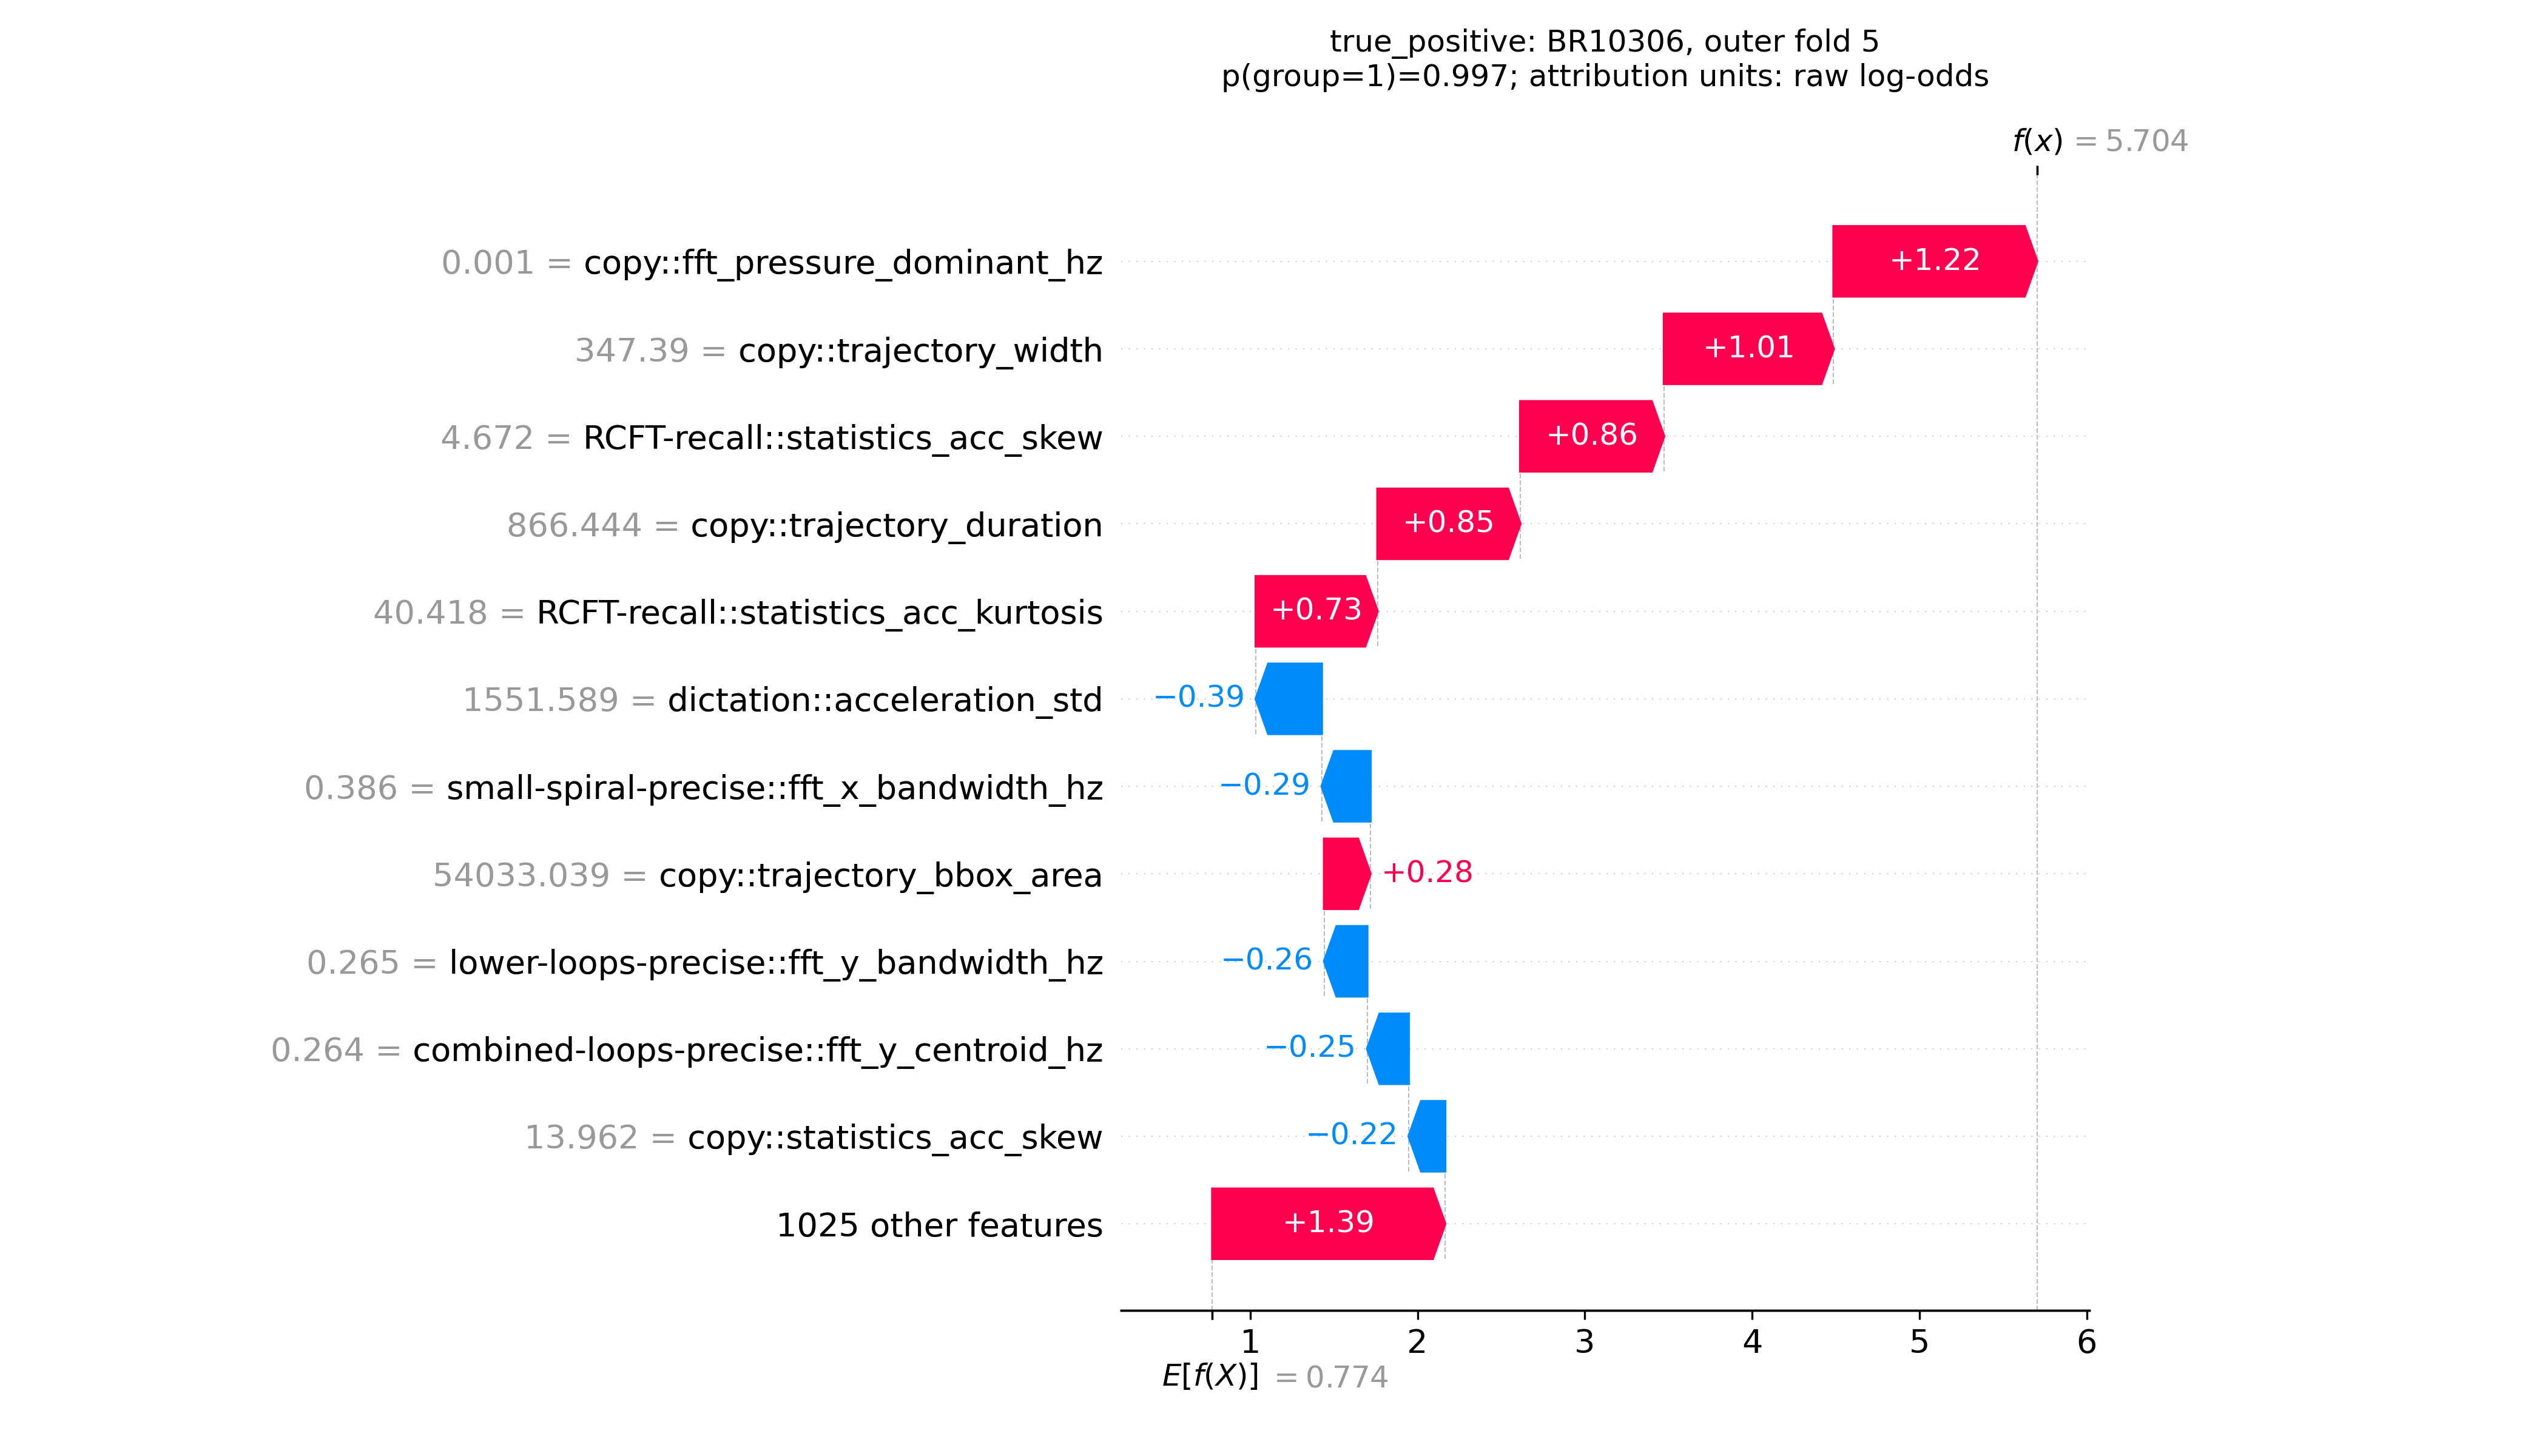

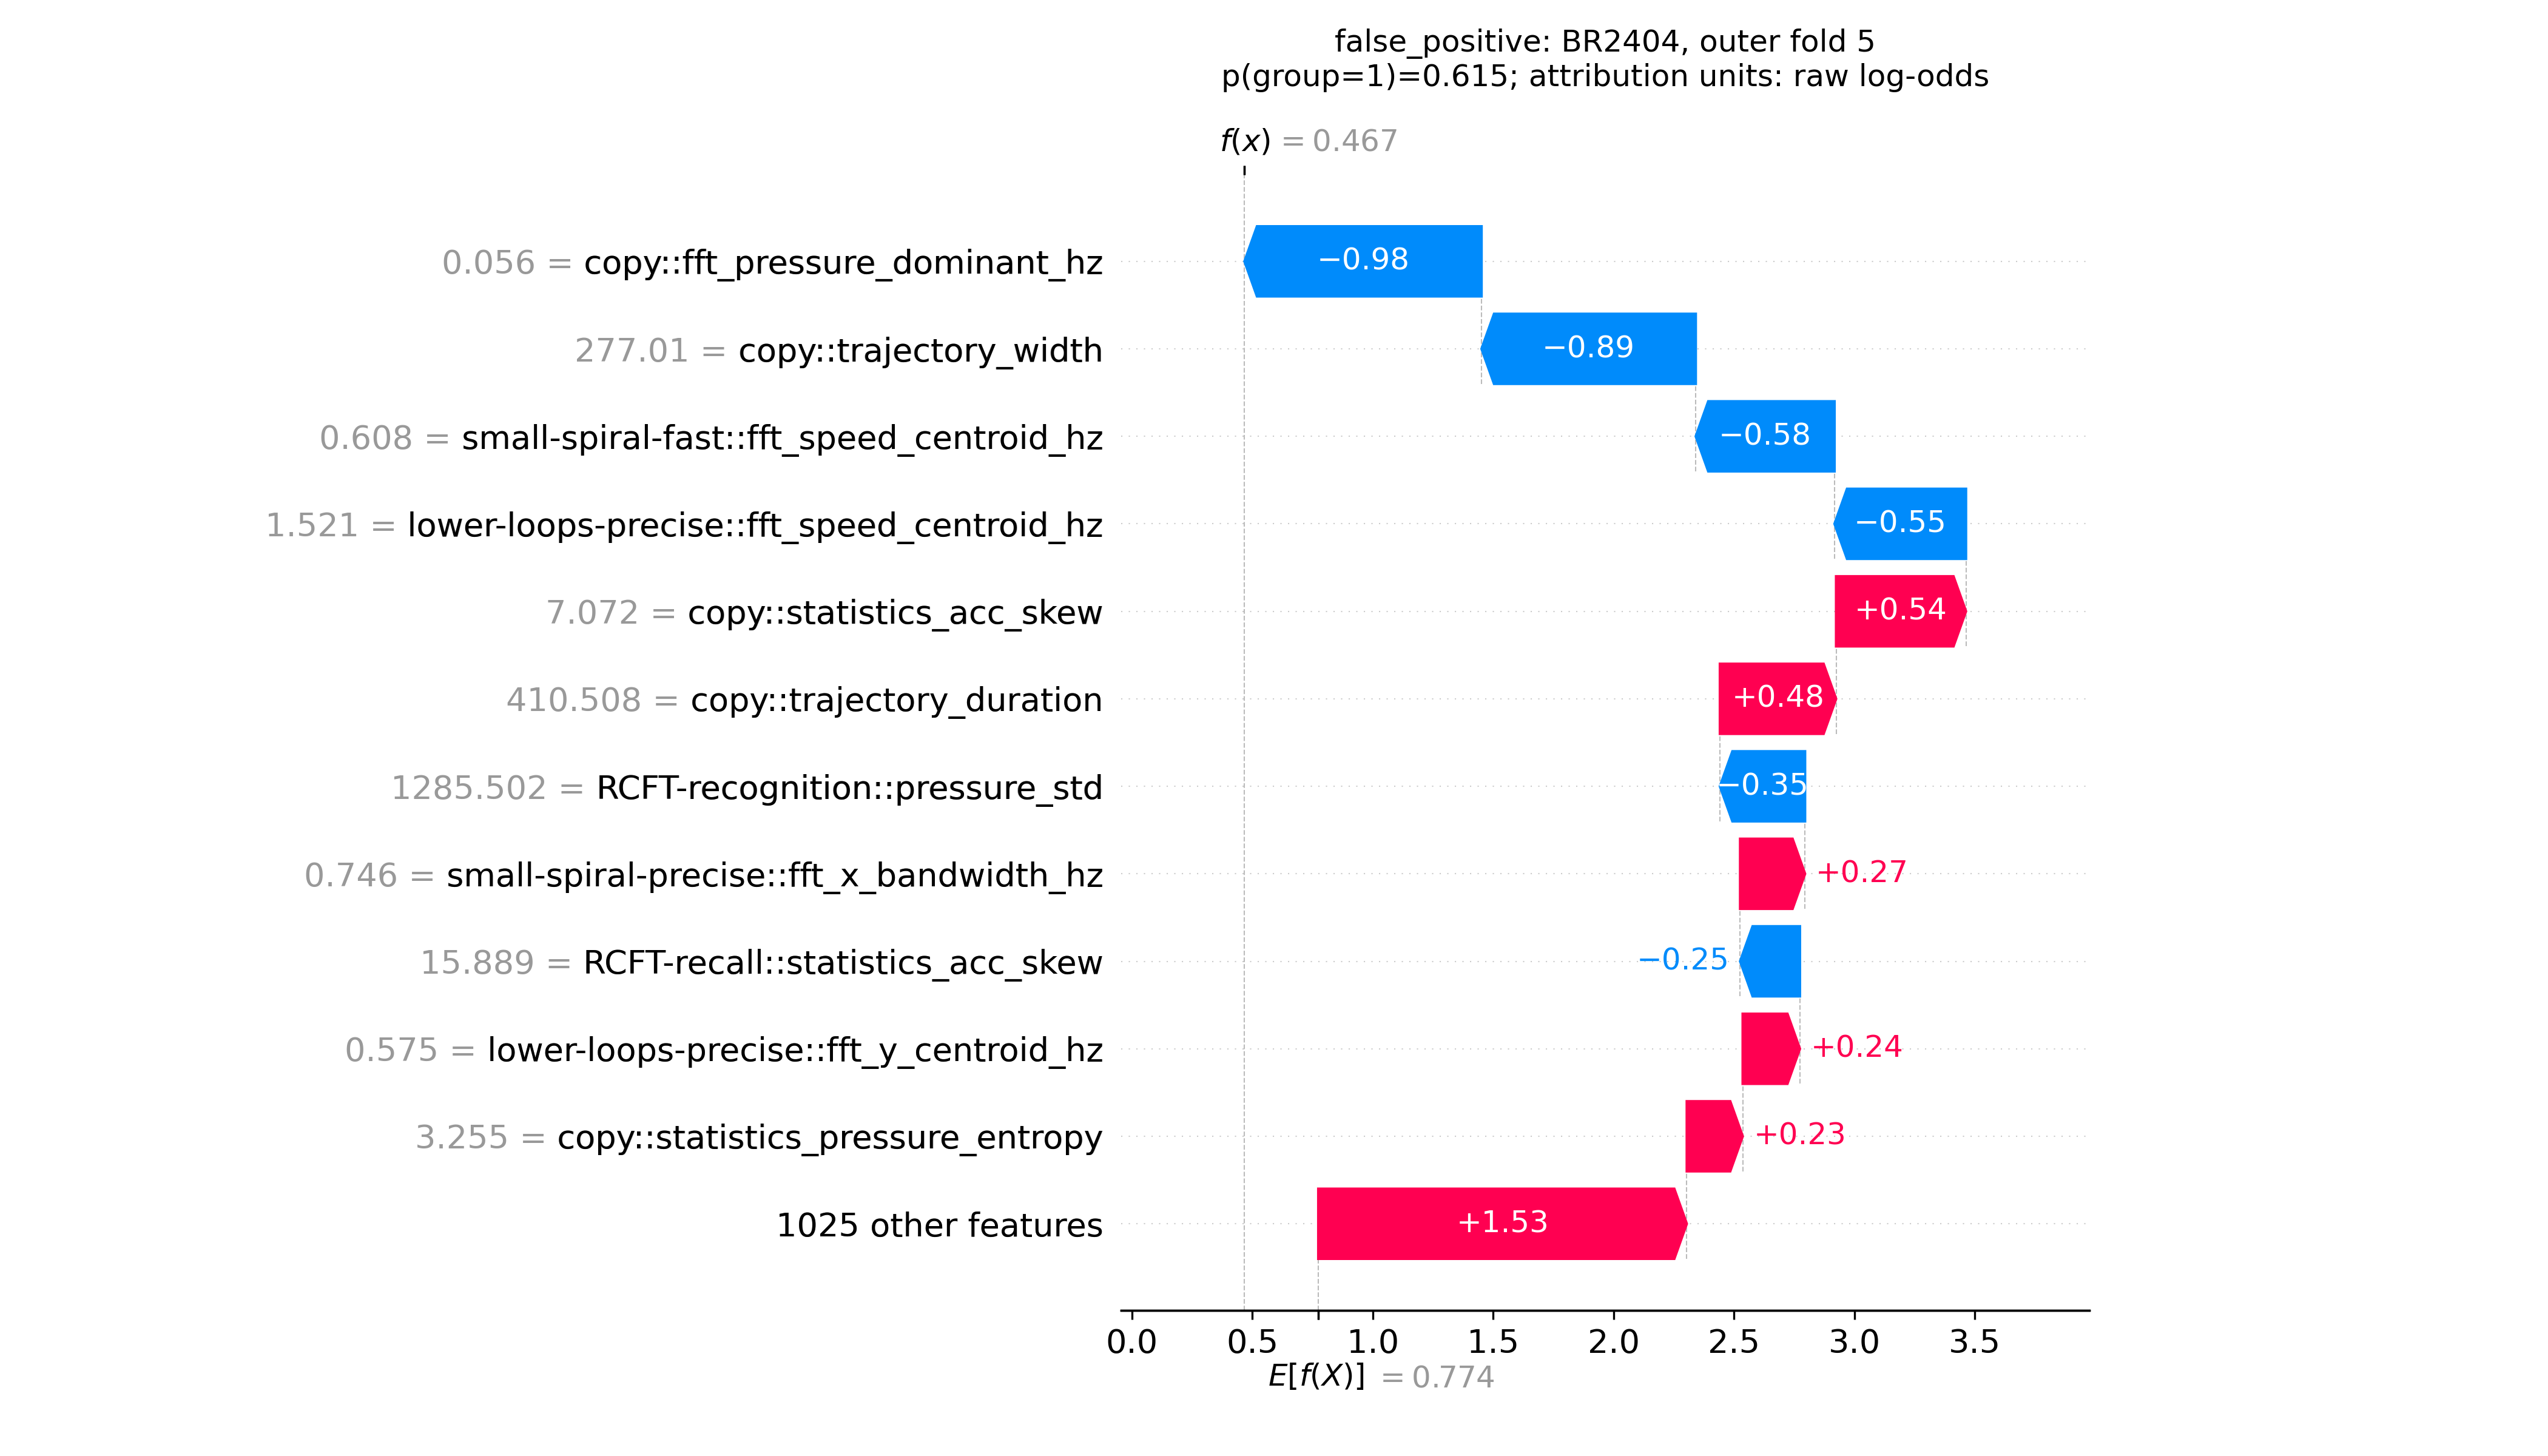

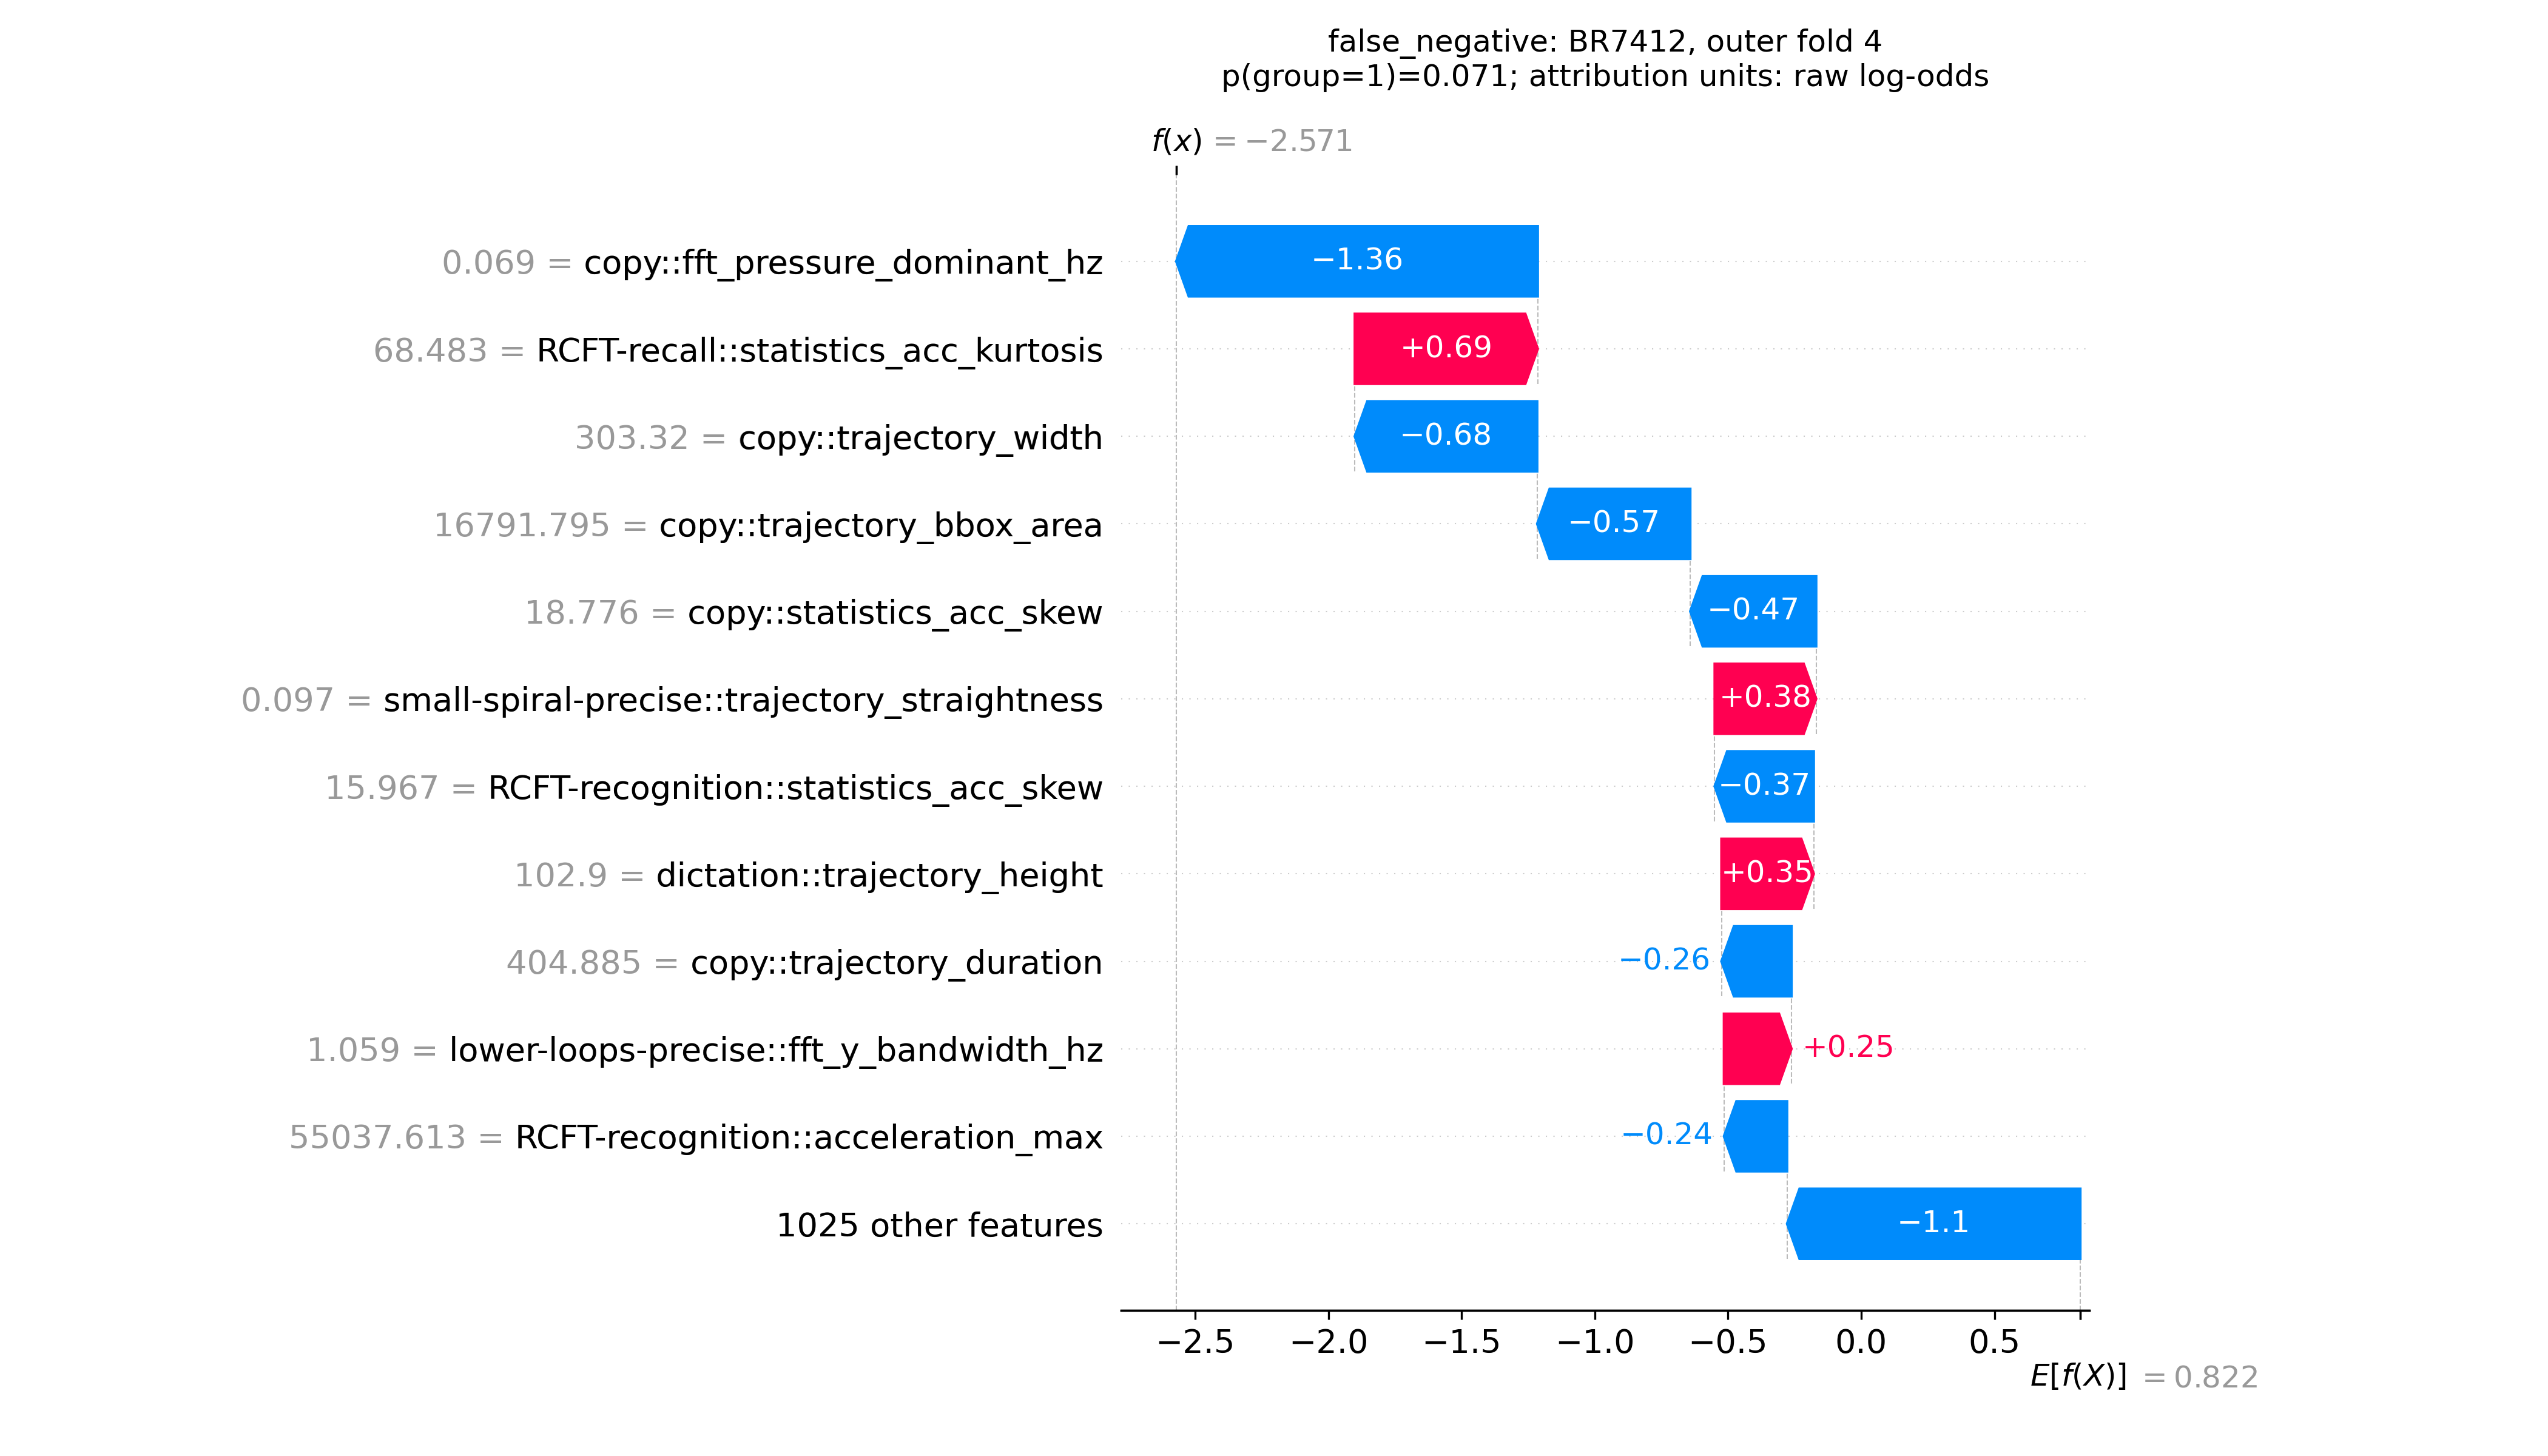

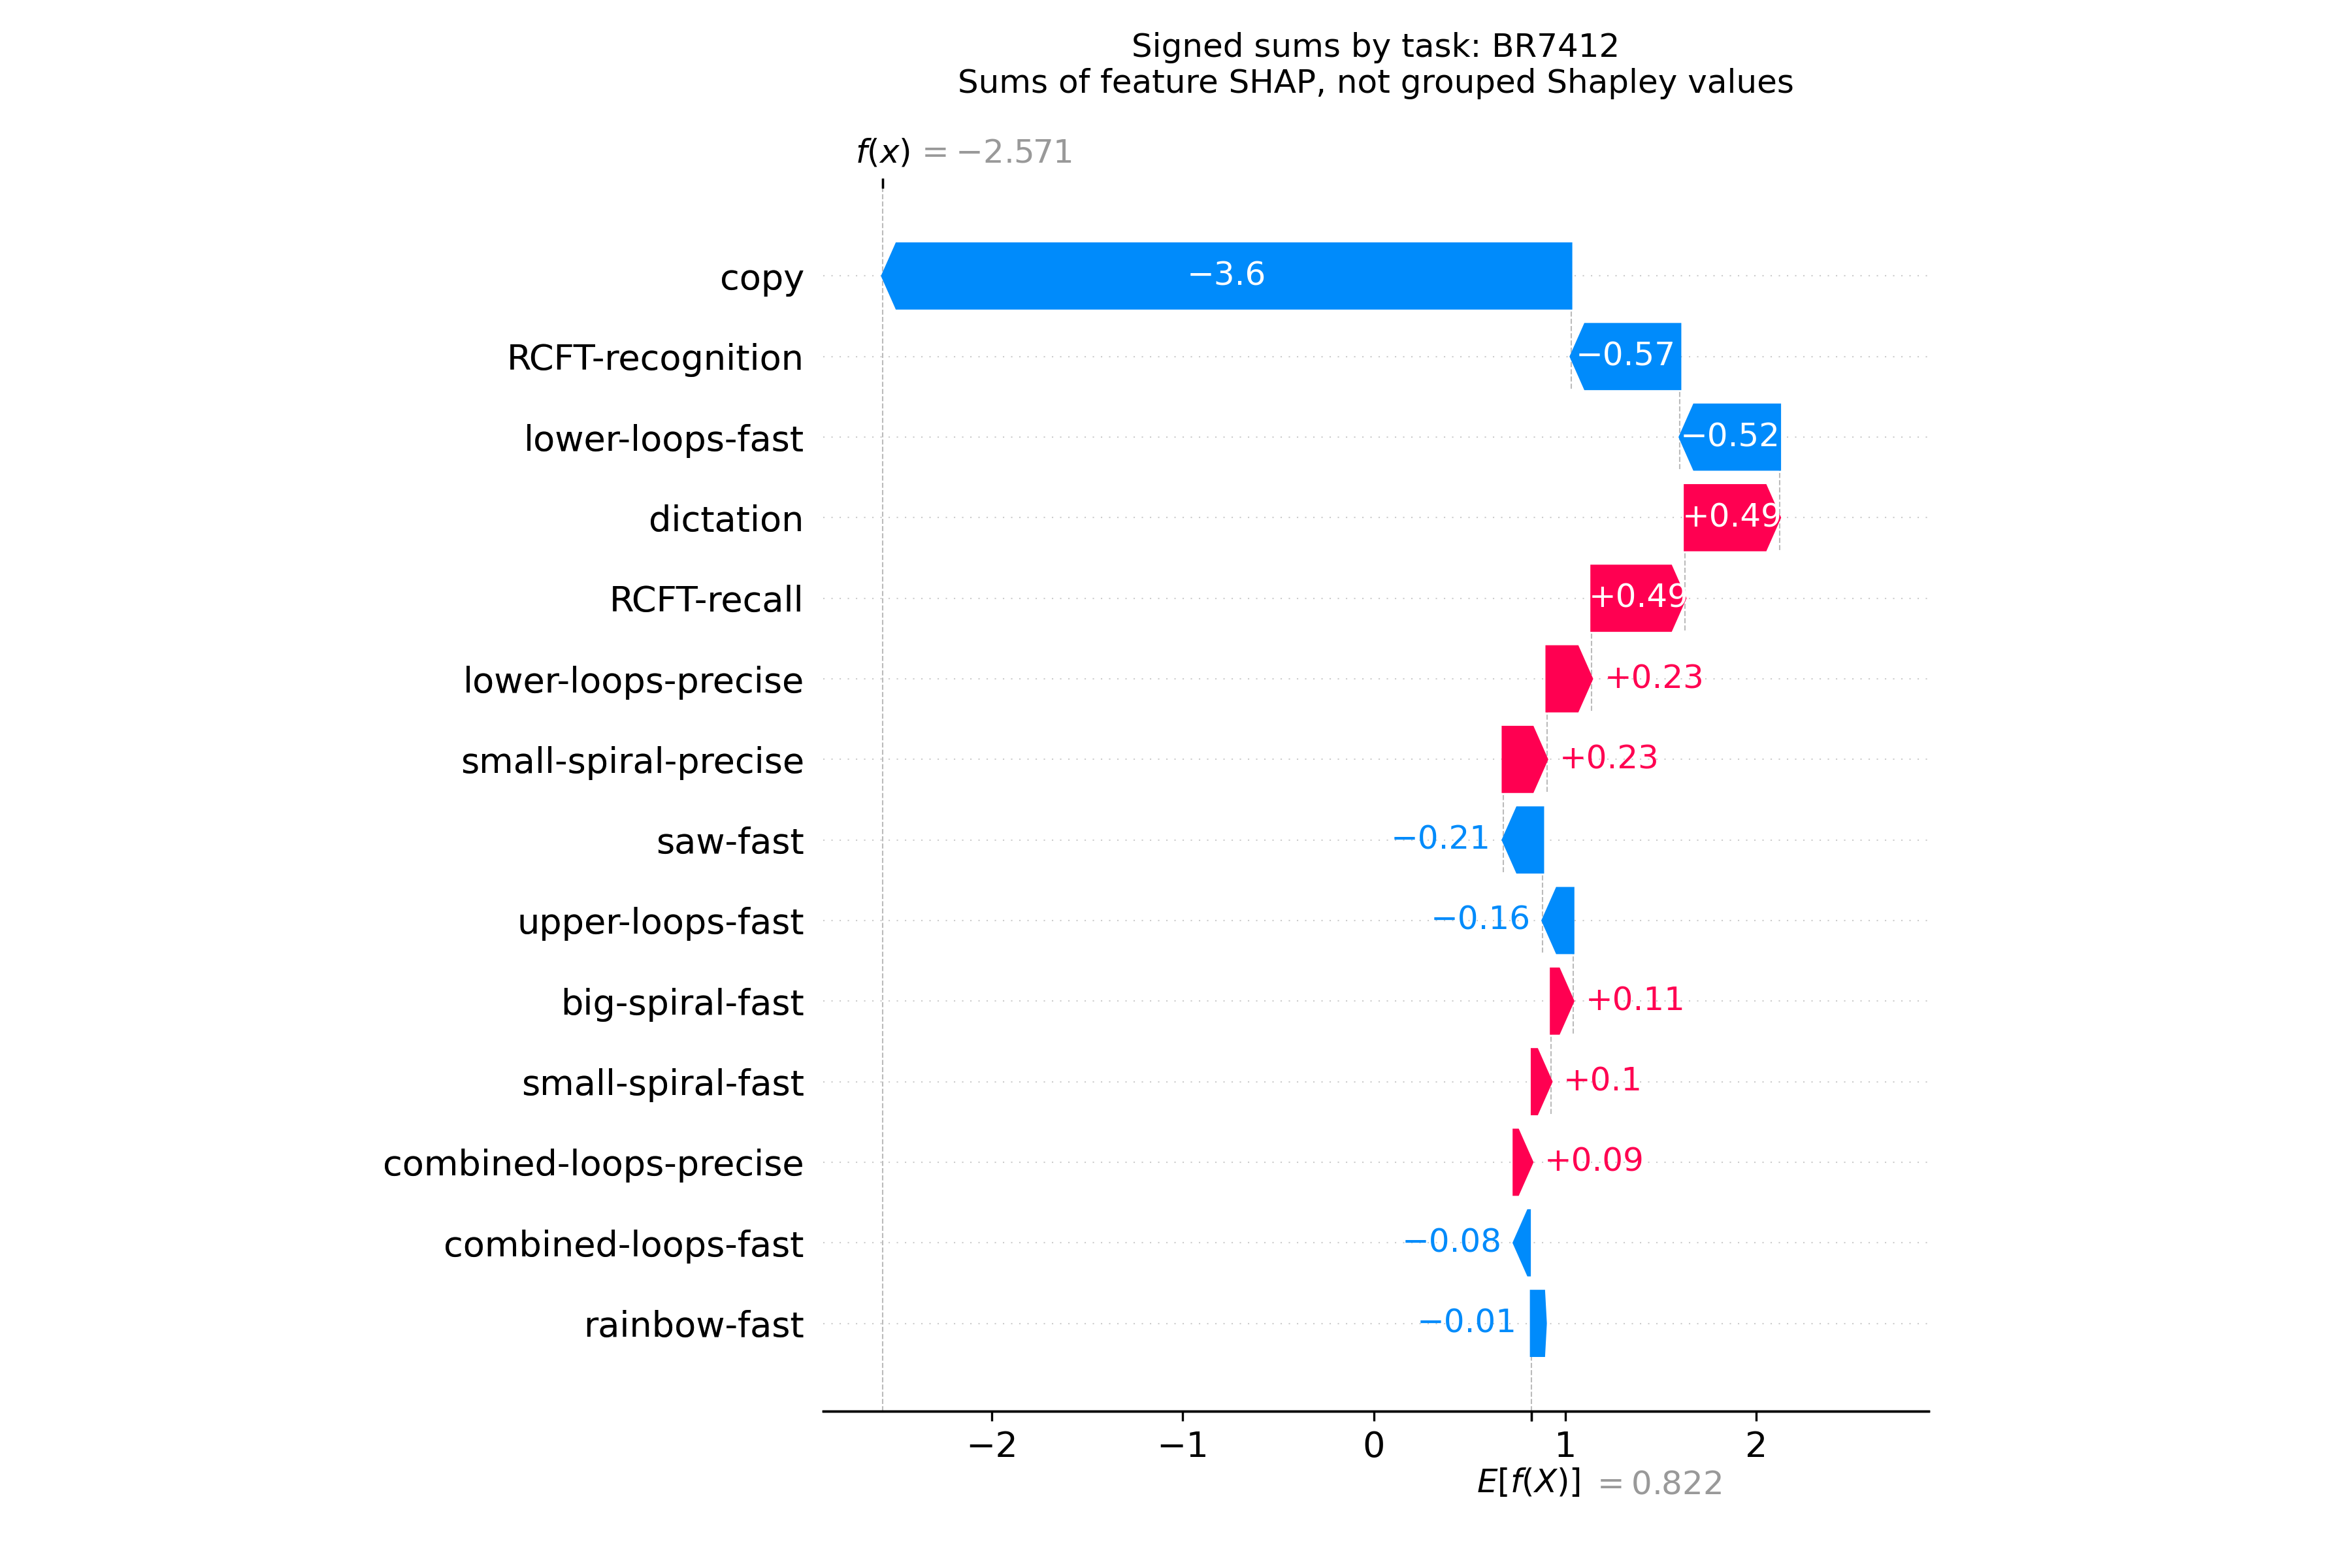

In [11]:
for name in ['waterfall_true_negative','waterfall_true_positive','waterfall_false_positive','waterfall_false_negative','task_signed_waterfall']:
    show(name)

## Kiểm chứng số liệu và báo cáo
Validation nghiên cứu tổng thể nằm ở `results/kinematic_xai/validation.json`.

In [12]:
validation=json.loads((OUT/'numeric_validation.json').read_text())
display(pd.DataFrame([validation['checks']]))
display(Markdown('[Đọc báo cáo nghiên cứu tiếng Việt](../results/kinematic_xai/REPORT_VI.md)'))

,protected_baseline_files,outer_folds,participants,features,tasks,source_groups,baseline_oof_matches,baseline_checkpoints_reconstructed,raw_additivity_passed,max_raw_additivity_error,max_sigmoid_probability_error,permutation_evaluations_replayed,loto_models_validated,ablation_prediction_rows,train_only_models_validated,train_only_id_separation_passed,all_task_and_group_aggregates_checked,paired_prediction_changes_checked
0,440,6,258,1036,14,12,True,0,True,7.105427e-15,1.110223e-16,4680,84,7224,18,True,True,True


[Đọc báo cáo nghiên cứu tiếng Việt](../results/kinematic_xai/REPORT_VI.md)